# Limpieza y transformación de BaseUnificada

Este cuaderno sigue el orden del plan en `docs/plan_limpieza_datos.md`.
La integración previa se conserva en el libro de manejo y la entrada congelada.

**Este cuaderno ejecuta L00 a L10:** identificación de la entrada,
reconstrucción comprobada de la procedencia y estandarización textual mediante
catálogos explícitos. L01 deja documentadas las decisiones económicas, temporales
y de catálogo que siguen pendientes; no las da por resueltas. L03 representa las
ausencias de las demás variables y conserva sus motivos en controles separados.
L04 interpreta tipos con reglas explícitas, presenta fechas como AAAA-MM-DD y
mantiene importes decimales exactos en COP; las alertas no se corrigen automáticamente.

L06 consolida únicamente repeticiones exactas de la misma fuente y conserva todos
sus orígenes. Las filas con diferencias se mantienen pendientes de conciliación.
No se imputan valores, se altera el valor numérico de importes ni se corrigen fechas
por aproximación. El resultado es una base preparada para revisión y análisis
descriptivo provisional, con decisiones administrativas pendientes. L02 conserva los marcadores recibidos;
L03 aplica las reglas de ausencia documentadas sin completar datos por suposición.
Los vacíos y nan de identificadores se conservan y se revisan mediante controles.
L10 complementa y consolida los dos parciales con evidencia interna y realiza la
exploración descriptiva del consolidado y de la cohorte principal sin solapamientos.

Ejecutar desde el principio con el Python del proyecto y los grupos `notebooks`
y `excel` de uv. Guardar el notebook antes de ejecutarlo para registrar su versión.

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
from zoneinfo import ZoneInfo
from io import BytesIO
import base64
import csv
import hashlib
import io
import json
import re
import struct
import sys
import unicodedata
import zipfile
import xml.etree.ElementTree as ET

import pandas as pd
from IPython.display import display, Markdown
from openpyxl import Workbook, load_workbook
from openpyxl.worksheet.table import Table, TableStyleInfo
from openpyxl.utils import get_column_letter

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'scripts'))
from exportar_base_unificada import preserve_empty_text
from analizar_relaciones_taller_2 import profile

SOURCE = ROOT / 'data/prepared/taller_2/BaseUnificada.csv'
META = json.loads(SOURCE.with_suffix('.metadata.json').read_text(encoding='utf8'))
RULE_PATH = ROOT / 'config/limpieza/estandarizacion_v1.json'
RULES = json.loads(RULE_PATH.read_text(encoding='utf8'))
INPUT_SHA = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
assert INPUT_SHA == META['archivos'][SOURCE.name]['sha256'], 'La entrada cambió de versión'
RULE_SHA = hashlib.sha256(RULE_PATH.read_bytes()).hexdigest()
NOTEBOOK = ROOT / 'notebooks/02_limpieza_base_unificada.ipynb'
saved_notebook = json.loads(NOTEBOOK.read_text(encoding='utf8'))
saved_code = '\n'.join(''.join(c['source']) if isinstance(c['source'], list) else c['source']
                       for c in saved_notebook['cells'] if c['cell_type'] == 'code')
CODE_SHA = hashlib.sha256(saved_code.encode()).hexdigest()
RUN_ID = f"{RULES['version']}_{INPUT_SHA[:10]}_{RULE_SHA[:8]}_{CODE_SHA[:8]}"

## L00. Entrada congelada e identificación de las filas

Se leen las 18 columnas como texto para que pandas no interprete periodos como fechas,
ni convierta nan o ausencias a valores faltantes por su cuenta. La conversión de tipos
de negocio corresponde a L04. El índice BU identifica filas de esta versión, no personas.

In [2]:
df_entrada = pd.read_csv(SOURCE, dtype=str, keep_default_na=False, na_filter=False,
                        encoding='utf-8-sig')
original = df_entrada.copy(deep=True)
N = len(original)
HEADERS = list(original.columns)
assert N == META['filas_sin_encabezado'] == 5640
assert HEADERS == META['encabezados'] and len(HEADERS) == 18
ids_fila = pd.Series([f'BU{i:06d}' for i in range(1, N + 1)], index=original.index)
inventario = pd.read_csv(ROOT / 'reports/limpieza/inventario_entrada.csv',
                         dtype=str, keep_default_na=False, encoding='utf-8-sig')
assert inventario['id_fila_entrada'].tolist() == ids_fila.tolist()
assert set(inventario['sha256_archivo_entrada']) == {INPUT_SHA}
diagnostico_inicial = profile(original.to_dict('records'))
display(pd.DataFrame([
    ['Filas', N], ['Columnas de negocio', len(HEADERS)],
    ['registro_id distintos', original['registro_id'].nunique()],
    ['Repeticiones exactas adicionales', int(original.duplicated().sum())],
    ['Filas con facultad sin asignar', int(original['facultad'].eq('').sum())]
], columns=['Control', 'Resultado']))

,Control,Resultado
0,Filas,5640
1,Columnas de negocio,18
2,registro_id distintos,5500
3,Repeticiones exactas adicionales,38
4,Filas con facultad sin asignar,27


## L01. Procedencia y decisiones pendientes

Se utiliza el libro de manejo que produjo la exportación. Se exige que su hash coincida
con los metadatos y se comprueba el orden de Table.Combine. Cada bloque se contrasta
con las 15 columnas de su hoja fuente, admitiendo solo las operaciones textuales
ya documentadas en la integración. No se asigna origen solo porque una fila ocupe
una posición o tenga un identificador REG.

Esto valida la procedencia dentro del libro congelado. No convierte el identificador
Oracle en identificador institucional de persona ni resuelve cuál fuente tiene razón.

In [3]:
def serializar(valor):
    return '' if valor is None else str(valor)

def limpiar_externo(valor):
    return ''.join(c for c in unicodedata.normalize('NFC', valor)
                   if unicodedata.category(c) != 'Cc').strip()

MANEJO = ROOT / META['libro_origen']
manejo_bytes = MANEJO.read_bytes()
assert hashlib.sha256(manejo_bytes).hexdigest() == META['sha256_libro_origen']
with zipfile.ZipFile(BytesIO(manejo_bytes)) as archive:
    mashup = base64.b64decode(ET.fromstring(archive.read('customXml/item1.xml')).text)
    package_size = struct.unpack_from('<I', mashup, 4)[0]
    with zipfile.ZipFile(BytesIO(mashup[8:8 + package_size])) as package:
        codigo_integracion = package.read('Formulas/Section1.m').decode('utf-8-sig')
assert re.search(r'Table\.Combine\(\{Caso2_Admisiones_Universitarias_Principal,\s*'
                 r'Caso2_CRM_Admisiones,\s*Caso2_Oracle_Admisiones\}\)', codigo_integracion)

origenes = [('Principal', 'Caso2_Admisiones_Universitarias', 5040),
            ('CRM', 'Caso2_CRM_Admisiones', 100),
            ('Oracle', 'Caso2_Oracle_Admisiones', 500)]
columnas_presentacion = {'programa', 'modalidad', 'canal_captacion',
                        'estado_proceso', 'ciudad_residencia', 'asesor'}
def comparable_integracion(valor, columna):
    valor = serializar(valor)
    if columna in columnas_presentacion:
        return limpiar_externo(valor).casefold()
    if columna in {'registro_id', 'aspirante_id'}:
        return limpiar_externo(valor)
    return valor

procedencia = []
offset = 0
book = load_workbook(BytesIO(manejo_bytes), read_only=True, data_only=True)
for sistema, hoja, cantidad in origenes:
    cache = list(book[hoja].iter_rows(values_only=True))
    columnas = list(cache[0])
    filas = [dict(zip(columnas, fila)) for fila in cache[1:]]
    assert len(filas) == cantidad
    assert columnas == HEADERS[:15]
    bloque = original.iloc[offset:offset + cantidad].to_dict('records')
    for posicion, (recibida, consolidada) in enumerate(zip(filas, bloque), 2):
        assert all(comparable_integracion(recibida[c], c) ==
                   comparable_integracion(consolidada[c], c) for c in HEADERS[:15]), (sistema, posicion)
        indice = offset + posicion - 2
        procedencia.append({'id_fila_entrada': ids_fila.iloc[indice],
                           'origen_sistema': sistema, 'hoja_evidencia': hoja,
                           'fila_hoja_evidencia': posicion,
                           'registro_id': consolidada['registro_id'],
                           'sha256_libro_evidencia': META['sha256_libro_origen']})
    offset += cantidad
book.close()
assert offset == N
origen_df = pd.DataFrame(procedencia)
assert origen_df['id_fila_entrada'].is_unique
display(origen_df.groupby('origen_sistema').size().rename('Filas verificadas').to_frame())

,Filas verificadas
origen_sistema,
CRM,100
Oracle,500
Principal,5040


In [4]:
decisiones_pendientes = pd.DataFrame([
    ['Identidad de solicitud', 'Conservar repeticiones; no definir personas o solicitudes únicas por registro_id solamente.'],
    ['Importes CRM', 'El valor integra base y derechos. Mantenerlo hasta acordar una medida comparable entre fuentes.'],
    ['Fechas Oracle', 'Conservar y señalar diferencias; no intercambiar día y mes ni sustituir fechas en esta etapa.'],
    ['Catálogo', 'La selección de Data Analytics y otros ajustes quedan como decisiones documentadas pendientes de validación.'],
    ['Asignaciones fuzzy', 'Revisar las denominaciones asignadas desde la evidencia de integración; no validar facultades solo por coincidencia.']
], columns=['Decisión', 'Tratamiento durante L02'])
display(decisiones_pendientes)

,Decisión,Tratamiento durante L02
0,Identidad de solicitud,Conservar repeticiones; no definir personas o ...
1,Importes CRM,El valor integra base y derechos. Mantenerlo h...
2,Fechas Oracle,Conservar y señalar diferencias; no intercambi...
3,Catálogo,La selección de Data Analytics y otros ajustes...
4,Asignaciones fuzzy,Revisar las denominaciones asignadas desde la ...


### Alcance acordado sobre identificadores

La revisión de identificadores entre fuentes se pospone hasta los cruces. Los códigos
Oracle y los de las demás fuentes se conservan; no necesitan coincidir para continuar
la estandarización. No se fusionan personas o solicitudes, no se cambia nan del
identificador ni se eliminan filas por este motivo en las primeras etapas. Los conteos
son diagnóstico y el índice BU sirve para auditar filas, no para reemplazar códigos.

## L02. Estandarización de textos y categorías

La regla usa espacios y acentos solo para buscar en un catálogo explícito. Se guarda
la denominación acordada, con sus tildes. No realiza coincidencia difusa ni asigna
valores desconocidos a la opción más cercana. Los desconocidos quedan intactos y señalados.

Se homologan los periodos como texto. La conversión a códigos enteros 20252, 20261 y
20262 permanece para L04. Fechas, puntajes, importes y duración se mantienen exactamente
como fueron recibidos. nan no se trata todavía como ausencia: corresponde a L03.

In [5]:
def clave_catalogo(valor):
    texto = re.sub(r'\s+', ' ', limpiar_externo(valor)).casefold()
    return ''.join(c for c in unicodedata.normalize('NFD', texto)
                   if unicodedata.category(c) != 'Mn')

catalogos = {}
for columna, valores in RULES['categorias'].items():
    mapping = {clave_catalogo(v): v for v in valores}
    assert len(mapping) == len(valores), f'Catálogo ambiguo: {columna}'
    catalogos[columna] = mapping
periodos = {clave_catalogo(k): v for k, v in RULES['periodos'].items()}
assert (set(catalogos) | {'periodo_academico', 'correo'} |
        set(RULES['identificadores']) | set(RULES['sin_transformacion_en_esta_etapa'])) == set(HEADERS)

def estandarizar(valor, columna):
    if columna in catalogos:
        return catalogos[columna].get(clave_catalogo(valor), valor)
    if columna == 'periodo_academico':
        return periodos.get(clave_catalogo(valor), valor)
    if columna in RULES['identificadores']:
        return limpiar_externo(valor)
    if columna == 'correo':
        correo = valor.strip()
        if correo.count('@') == 1:
            local, dominio = correo.split('@')
            return local + '@' + dominio.lower()
        return correo
    return valor

display(pd.DataFrame([
    {'columna': c, 'tratamiento': 'Catálogo explícito' if c in catalogos else
     'Equivalencias de periodo, aún como texto' if c == 'periodo_academico' else
     'Identificador: espacios externos y controles' if c in RULES['identificadores'] else
     'Espacios externos y dominio del correo' if c == 'correo' else
     'Sin cambios en esta etapa'} for c in HEADERS
]))

,columna,tratamiento
0,registro_id,Identificador: espacios externos y controles
1,aspirante_id,Identificador: espacios externos y controles
2,fecha_solicitud,Sin cambios en esta etapa
3,programa,Catálogo explícito
4,modalidad,Catálogo explícito
5,canal_captacion,Catálogo explícito
6,estado_proceso,Catálogo explícito
7,puntaje_admision,Sin cambios en esta etapa
8,documentos_completos,Catálogo explícito
9,valor_matricula_cop,Sin cambios en esta etapa


In [6]:
df_estandarizada = original.copy(deep=True)
cambios = []
pasos = []
incidencias = []
for numero, columna in enumerate(HEADERS, 1):
    regla = f'E{numero:02d}'
    antes = df_estandarizada[columna].copy()
    despues = antes.map(lambda v: estandarizar(v, columna))
    modificadas = antes.ne(despues)
    for indice in antes.index[modificadas]:
        cambios.append({'id_ejecucion': RUN_ID, 'paso': 'L02', 'regla': regla,
                        'id_fila_entrada': ids_fila.loc[indice],
                        'registro_id': original.loc[indice, 'registro_id'],
                        'columna': columna, 'valor_anterior': antes.loc[indice],
                        'valor_posterior': despues.loc[indice],
                        'tipo_anterior': 'texto de entrada', 'tipo_posterior': 'texto',
                        'motivo': 'Estandarización explícita; no cambia identidad ni elimina filas'})
    df_estandarizada[columna] = despues
    pasos.append({'id_ejecucion': RUN_ID, 'paso': 'L02', 'regla': regla,
                  'columna': columna, 'version_reglas': RULES['version'],
                  'filas_antes': N, 'filas_despues': len(df_estandarizada),
                  'filas_modificadas_unicas': int(modificadas.sum()),
                  'celdas_valor_modificado': int(modificadas.sum()),
                  'celdas_tipo_modificado': 0, 'filas_excluidas': 0,
                  'repeticiones_consolidadas': 0, 'filas_generadas': 0})
    if columna in catalogos or columna == 'periodo_academico':
        aceptados = catalogos[columna] if columna in catalogos else periodos
        for indice, valor in antes.items():
            if valor and clave_catalogo(valor) not in aceptados:
                incidencias.append({'id_ejecucion': RUN_ID, 'id_fila_entrada': ids_fila.loc[indice],
                                    'columna': columna, 'valor': valor,
                                    'motivo': 'Categoría sin equivalencia; valor conservado'})

pasos_df = pd.DataFrame(pasos)
cambios_df = pd.DataFrame(cambios, columns=['id_ejecucion', 'paso', 'regla', 'id_fila_entrada',
    'registro_id', 'columna', 'valor_anterior', 'valor_posterior', 'tipo_anterior', 'tipo_posterior', 'motivo'])
incidencias_df = pd.DataFrame(incidencias, columns=['id_ejecucion', 'id_fila_entrada', 'columna', 'valor', 'motivo'])
display(pasos_df[['regla', 'columna', 'filas_antes', 'filas_despues', 'celdas_valor_modificado', 'filas_excluidas']])

,regla,columna,filas_antes,filas_despues,celdas_valor_modificado,filas_excluidas
0,E01,registro_id,5640,5640,0,0
1,E02,aspirante_id,5640,5640,0,0
2,E03,fecha_solicitud,5640,5640,0,0
3,E04,programa,5640,5640,3112,0
4,E05,modalidad,5640,5640,0,0
5,E06,canal_captacion,5640,5640,2799,0
6,E07,estado_proceso,5640,5640,1291,0
7,E08,puntaje_admision,5640,5640,0,0
8,E09,documentos_completos,5640,5640,2039,0
9,E10,valor_matricula_cop,5640,5640,0,0


### Antes y después de las equivalencias

Cada fila de esta tabla describe una transformación de valor y cuántas celdas afecta.
La suma de cambios de varias columnas no equivale a filas eliminadas ni a personas.

In [7]:
equivalencias = (cambios_df.groupby(['columna', 'valor_anterior', 'valor_posterior'], dropna=False)
                 .size().reset_index(name='celdas_modificadas'))
display(equivalencias)
display(Markdown(f"**Filas con algún cambio:** {cambios_df['id_fila_entrada'].nunique():,}. "
                 f"**Celdas modificadas:** {len(cambios_df):,}. **Filas eliminadas: 0.**"))

,columna,valor_anterior,valor_posterior,celdas_modificadas
0,asesor,Sin Asignar,Sin asignar,1132
1,canal_captacion,Feria Universitaria,Feria universitaria,963
2,canal_captacion,Landing Page,Landing page,914
3,canal_captacion,Web Institucional,Web institucional,922
4,ciudad_residencia,Bogota,Bogotá,605
5,ciudad_residencia,Popayan,Popayán,509
6,ciudad_residencia,Santander De Quilichao,Santander de Quilichao,632
7,documentos_completos,SI,Sí,1019
8,documentos_completos,sí,Sí,1020
9,estado_proceso,Documentación Pendiente,Documentación pendiente,656


**Filas con algún cambio:** 5,404. **Celdas modificadas:** 14,209. **Filas eliminadas: 0.**

In [8]:
comparacion_frecuencias = []
for columna in [*catalogos, 'periodo_academico']:
    antes = original[columna].value_counts(dropna=False)
    despues = df_estandarizada[columna].value_counts(dropna=False)
    for valor in sorted(set(antes.index) | set(despues.index)):
        comparacion_frecuencias.append({'columna': columna, 'valor': valor,
            'antes': int(antes.get(valor, 0)), 'despues': int(despues.get(valor, 0))})
frecuencias_df = pd.DataFrame(comparacion_frecuencias)
display(frecuencias_df[frecuencias_df['columna'].isin(['programa', 'documentos_completos',
                                                      'ciudad_residencia', 'periodo_academico'])])

,columna,valor,antes,despues
0,programa,,25,25
1,programa,Administración De Empresas,595,0
2,programa,Administración de Empresas,0,595
3,programa,Contaduría Pública,631,631
4,programa,Derecho,1259,1259
5,programa,Especializacion En Data Analytics,574,0
6,programa,Especialización En Data Analytics,676,0
7,programa,Especialización En Gerencia,619,0
8,programa,Especialización en Data Analytics,0,1250
9,programa,Especialización en Gerencia,0,619


## Controles y casos que siguen pendientes

Unificar una tilde no resuelve un duplicado ni valida la facultad asignada. Se preservan
las ausencias y marcadores recibidos. El importe CRM continúa con el concepto calculado
en la integración; no se compara como si ese concepto estuviera confirmado para todas
las fuentes. Las columnas pendientes se conservaron sin modificar.

In [9]:
sin_cambios = RULES['sin_transformacion_en_esta_etapa']
controles = pd.DataFrame([
    ['Filas conservadas', len(df_estandarizada) == N],
    ['18 columnas y orden original', list(df_estandarizada.columns) == HEADERS],
    ['Entrada en memoria intacta', df_entrada.equals(original)],
    ['Identificadores de negocio intactos', df_estandarizada[['registro_id', 'aspirante_id']].equals(original[['registro_id', 'aspirante_id']])],
    ['Fechas, puntajes, importes y duración intactos', df_estandarizada[sin_cambios].equals(original[sin_cambios])],
    ['Índice de filas completo y en el mismo orden', df_estandarizada.index.equals(original.index)],
    ['Todas las procedencias verificadas', len(origen_df) == N],
    ['Categorías desconocidas conservadas', all(df_estandarizada.loc[int(i[2:]) - 1, c] == v
        for i, c, v in incidencias_df[['id_fila_entrada', 'columna', 'valor']].itertuples(index=False, name=None))],
    ['Segunda aplicación no cambia valores', all(df_estandarizada[c].map(lambda v: estandarizar(v, c)).equals(df_estandarizada[c]) for c in HEADERS)],
    ['CSV de entrada intacto', hashlib.sha256(SOURCE.read_bytes()).hexdigest() == INPUT_SHA]
], columns=['Control', 'Correcto'])
assert controles['Correcto'].all()
display(controles)
display(pd.DataFrame([
    ['Repeticiones exactas adicionales', int(original.duplicated().sum()), int(df_estandarizada.duplicated().sum())],
    ['Aspirantes vacíos', int(original['aspirante_id'].eq('').sum()), int(df_estandarizada['aspirante_id'].eq('').sum())],
    ['Aspirantes nan', int(original['aspirante_id'].eq('nan').sum()), int(df_estandarizada['aspirante_id'].eq('nan').sum())],
    ['Programas vacíos', int(original['programa'].eq('').sum()), int(df_estandarizada['programa'].eq('').sum())],
    ['Programas sin especificar', int(original['programa'].eq('Sin Especificar').sum()), int(df_estandarizada['programa'].eq('Sin especificar').sum())],
    ['Facultades sin asignar', int(original['facultad'].eq('').sum()), int(df_estandarizada['facultad'].eq('').sum())]
], columns=['Situación', 'Antes', 'Después']))

,Control,Correcto
0,Filas conservadas,True
1,18 columnas y orden original,True
2,Entrada en memoria intacta,True
3,Identificadores de negocio intactos,True
4,"Fechas, puntajes, importes y duración intactos",True
5,Índice de filas completo y en el mismo orden,True
6,Todas las procedencias verificadas,True
7,Categorías desconocidas conservadas,True
8,Segunda aplicación no cambia valores,True
9,CSV de entrada intacto,True


,Situación,Antes,Después
0,Repeticiones exactas adicionales,38,38
1,Aspirantes vacíos,92,92
2,Aspirantes nan,4,4
3,Programas vacíos,25,25
4,Programas sin especificar,2,2
5,Facultades sin asignar,27,27


## Guardado del estado intermedio y de la auditoría

La carpeta de ejecución se identifica mediante versión de reglas y hashes de entrada,
reglas y código. Repetir la misma versión reconstruye el mismo estado de datos, sin
acumular nuevas filas. Los datos de partida no se sobrescriben.

Se exportan las 18 columnas de negocio, la procedencia comprobada, cambios por celda,
resumen por regla, equivalencias, controles y disposición de todas las filas. En esta
etapa cada entrada se conserva como salida individual.

In [10]:
DATA_OUT = ROOT / 'data/interim/taller_2' / RUN_ID
AUDIT_OUT = ROOT / 'reports/limpieza/ejecuciones' / RUN_ID
DATA_OUT.mkdir(parents=True, exist_ok=True)
AUDIT_OUT.mkdir(parents=True, exist_ok=True)
csv_path = DATA_OUT / 'BaseUnificada_Estandarizada.csv'
xlsx_path = DATA_OUT / 'BaseUnificada_Estandarizada.xlsx'
df_estandarizada.to_csv(csv_path, index=False, encoding='utf-8-sig', lineterminator='\n')
book = Workbook()
sheet = book.active
sheet.title = 'BaseUnificada_Estandarizada'
sheet.append(HEADERS)
output_rows = list(df_estandarizada.itertuples(index=False, name=None))
for fila in output_rows:
    sheet.append(fila)
table = Table(displayName='BaseUnificada_Estandarizada', ref=f'A1:{get_column_letter(len(HEADERS))}{N + 1}')
table.tableStyleInfo = TableStyleInfo(name='TableStyleMedium9', showRowStripes=True)
sheet.add_table(table)
sheet.freeze_panes = 'A2'
book.save(xlsx_path)
book.close()
preserve_empty_text(xlsx_path, output_rows)
assert pd.read_csv(csv_path, dtype=str, keep_default_na=False, na_filter=False,
                   encoding='utf-8-sig').equals(df_estandarizada)
verify_book = load_workbook(xlsx_path, read_only=True, data_only=True)
verify_rows = list(verify_book['BaseUnificada_Estandarizada'].iter_rows(values_only=True))
assert list(verify_rows[0]) == HEADERS and verify_rows[1:] == output_rows
verify_book.close()
OUTPUT_SHA = hashlib.sha256(csv_path.read_bytes()).hexdigest()

disposicion_df = pd.DataFrame({'id_ejecucion': RUN_ID, 'id_fila_entrada': ids_fila,
    'registro_id_original': original['registro_id'], 'estado_destino': 'conservada',
    'id_registro_salida': ids_fila, 'fila_csv_salida': range(2, N + 2),
    'sha256_archivo_salida': OUTPUT_SHA, 'motivo': 'L02 no elimina ni consolida filas'})
for nombre, frame in {
    'L01_procedencia.csv': origen_df, 'L01_decisiones_pendientes.csv': decisiones_pendientes,
    'L02_registro_pasos.csv': pasos_df, 'L02_cambios_por_celda.csv': cambios_df,
    'L02_equivalencias_observadas.csv': equivalencias, 'L02_frecuencias_antes_despues.csv': frecuencias_df,
    'L02_categorias_desconocidas.csv': incidencias_df, 'L02_controles.csv': controles,
    'L02_disposicion_filas.csv': disposicion_df
}.items():
    frame.to_csv(AUDIT_OUT / nombre, index=False, encoding='utf-8-sig', lineterminator='\n')

resumen = {'id_ejecucion': RUN_ID, 'ejecutado_en': datetime.now(ZoneInfo('America/Bogota')).isoformat(),
    'version_reglas': RULES['version'], 'sha256_entrada': INPUT_SHA, 'sha256_reglas': RULE_SHA,
    'sha256_codigo_notebook': CODE_SHA, 'filas_entrada': N, 'filas_salida': len(df_estandarizada),
    'columnas_negocio': len(HEADERS), 'filas_con_cambios': int(cambios_df['id_fila_entrada'].nunique()),
    'celdas_modificadas': len(cambios_df), 'filas_eliminadas': 0, 'filas_consolidadas': 0,
    'categorias_desconocidas': len(incidencias_df), 'controles_correctos': bool(controles['Correcto'].all()),
    'origenes_verificados': origen_df['origen_sistema'].value_counts().to_dict(),
    'repeticiones_exactas_antes': int(original.duplicated().sum()),
    'repeticiones_exactas_despues': int(df_estandarizada.duplicated().sum()),
    'archivos_datos': {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in [csv_path, xlsx_path]},
    'datos_intermedios': str(DATA_OUT.relative_to(ROOT)), 'auditoria': str(AUDIT_OUT.relative_to(ROOT)),
    'etapas': ['L00 entrada identificada', 'L01 procedencia verificada y decisiones documentadas', 'L02 estandarización textual'],
    'pendientes': ['L03 ausencias', 'L04 tipos y validaciones', 'L05 revisión de enriquecimiento',
                   'L06 duplicados exactos', 'L07 conciliación', 'L08 coherencia', 'L09 salida final']}
(AUDIT_OUT / 'resumen_ejecucion.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2) + '\n', encoding='utf8')
latest = ROOT / 'reports/limpieza/ultima_estandarizacion.json'
latest.write_text(json.dumps(resumen, ensure_ascii=False, indent=2) + '\n', encoding='utf8')
assert disposicion_df['id_fila_entrada'].nunique() == N
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == INPUT_SHA
display(pd.DataFrame([{'Etapa': 'L02', 'Filas de entrada': N, 'Filas de salida': N,
    'Filas con cambios': resumen['filas_con_cambios'], 'Celdas modificadas': len(cambios_df),
    'Filas eliminadas': 0, 'Controles correctos': resumen['controles_correctos']}]))
print('Datos intermedios:', DATA_OUT.relative_to(ROOT))
print('Auditoría:', AUDIT_OUT.relative_to(ROOT))

,Etapa,Filas de entrada,Filas de salida,Filas con cambios,Celdas modificadas,Filas eliminadas,Controles correctos
0,L02,5640,5640,5404,14209,0,True


Datos intermedios: data/interim/taller_2/estandarizacion_v1_f77076f7d8_150bd123_cd91e63a
Auditoría: reports/limpieza/ejecuciones/estandarizacion_v1_f77076f7d8_150bd123_cd91e63a


## L03. Tratamiento de ausencias con su motivo

Esta etapa toma el resultado L02 sin descartar registros. Representa como ausentes
los vacíos de columnas distintas de los identificadores y cuatro marcadores explícitos:
Sin especificar en programa, Pendiente en puntaje, por definir en importe y No aplica
en fecha de matrícula. Cada celda mantiene en la auditoría su texto anterior y motivo.

Pendiente en documentos y Sin asignar en asesor siguen siendo categorías. Los vacíos
y nan de los identificadores permanecen intactos. Un vacío se registra como no informado
en la base; no se presume su causa institucional ni se convierte en cero.

In [11]:
AUS_PATH = ROOT / 'config/limpieza/ausencias_v1.json'
AUS_RULES = json.loads(AUS_PATH.read_text(encoding='utf8'))
AUS_SHA = hashlib.sha256(AUS_PATH.read_bytes()).hexdigest()
L03_ID = f"{AUS_RULES['version']}_{OUTPUT_SHA[:10]}_{AUS_SHA[:8]}_{CODE_SHA[:8]}"
entrada_l03 = df_estandarizada.copy(deep=True)

def motivo_ausencia(valor, columna):
    if columna in AUS_RULES['columnas_excluidas']:
        return None
    if valor is None:
        return 'ya_ausente'
    if valor == '':
        return AUS_RULES['vacio_en_otra_columna']
    return AUS_RULES['marcadores_por_columna'].get(columna, {}).get(valor)

display(pd.DataFrame([
    {'Columna': 'Cualquier columna salvo identificadores', 'Valor recibido': 'Texto vacío',
     'Motivo': AUS_RULES['vacio_en_otra_columna']},
    *[{'Columna': c, 'Valor recibido': v, 'Motivo': motivo}
      for c, valores in AUS_RULES['marcadores_por_columna'].items() for v, motivo in valores.items()]
]))

,Columna,Valor recibido,Motivo
0,Cualquier columna salvo identificadores,Texto vacío,no_informado_en_base
1,programa,Sin especificar,sin_especificar
2,puntaje_admision,Pendiente,pendiente
3,valor_matricula_cop,por definir,por_definir
4,fecha_matricula,No aplica,no_aplica


In [12]:
df_ausencias = entrada_l03.astype(object).copy(deep=True)
cambios_l03 = []
pasos_l03 = []
for numero, columna in enumerate(HEADERS, 1):
    valores = []
    afectados = 0
    for indice, valor in entrada_l03[columna].items():
        motivo = motivo_ausencia(valor, columna)
        if motivo is not None and motivo != 'ya_ausente':
            valores.append(None)
            afectados += 1
            cambios_l03.append({'id_ejecucion': L03_ID, 'paso': 'L03', 'regla': f'A{numero:02d}',
                'id_fila_entrada': ids_fila.loc[indice],
                'registro_id': original.loc[indice, 'registro_id'], 'columna': columna,
                'valor_anterior': valor, 'valor_posterior': None,
                'tipo_anterior': 'texto vacío' if valor == '' else 'texto',
                'tipo_posterior': 'ausente', 'motivo_ausencia': motivo,
                'imputado': False})
        else:
            valores.append(valor)
    df_ausencias[columna] = pd.Series(valores, index=entrada_l03.index, dtype=object)
    pasos_l03.append({'id_ejecucion': L03_ID, 'paso': 'L03', 'regla': f'A{numero:02d}',
        'columna': columna, 'filas_antes': N, 'filas_despues': len(df_ausencias),
        'celdas_ausencia_normalizada': afectados, 'filas_excluidas': 0,
        'repeticiones_consolidadas': 0, 'filas_imputadas': 0,
        'tratamiento': 'Identificador sin cambios' if columna in AUS_RULES['columnas_excluidas']
                       else 'Aplicación de reglas explícitas de ausencia'})

audit_l03 = pd.DataFrame(cambios_l03)
pasos_l03_df = pd.DataFrame(pasos_l03)
motivos_l03 = (audit_l03.groupby(['columna', 'motivo_ausencia']).size()
               .reset_index(name='celdas'))
columnas_con_ausencias = motivos_l03['columna'].unique()
comparacion_l03 = pd.DataFrame([{'Columna': c,
    'Textos vacíos antes': int(entrada_l03[c].eq('').sum()),
    'Ausencias normalizadas después': int(df_ausencias[c].isna().sum()),
    'Valores con información conservada': int(df_ausencias[c].notna().sum())}
    for c in columnas_con_ausencias])
display(motivos_l03)
display(comparacion_l03)
display(Markdown(f"**Celdas con ausencia normalizada:** {len(audit_l03):,}. "
    f"**Filas afectadas:** {audit_l03['id_fila_entrada'].nunique():,}. "
    "**Filas eliminadas o imputadas: 0.**"))

,columna,motivo_ausencia,celdas
0,correo,no_informado_en_base,131
1,duracion_semestres,no_informado_en_base,27
2,facultad,no_informado_en_base,27
3,fecha_matricula,no_aplica,1369
4,fecha_matricula,no_informado_en_base,3065
5,nivel_formacion,no_informado_en_base,27
6,programa,no_informado_en_base,25
7,programa,sin_especificar,2
8,puntaje_admision,no_informado_en_base,200
9,puntaje_admision,pendiente,51


,Columna,Textos vacíos antes,Ausencias normalizadas después,Valores con información conservada
0,correo,131,131,5509
1,duracion_semestres,27,27,5613
2,facultad,27,27,5613
3,fecha_matricula,3065,4434,1206
4,nivel_formacion,27,27,5613
5,programa,25,27,5613
6,puntaje_admision,200,251,5389
7,valor_matricula_cop,907,942,4698


**Celdas con ausencia normalizada:** 5,866. **Filas afectadas:** 4,705. **Filas eliminadas o imputadas: 0.**

### Controles de L03

Una ausencia normalizada no equivale a una corrección de su causa. Se mantiene el
detalle por celda para distinguir los motivos aunque Excel o CSV los presenten vacíos.
La relación de identificadores pospuestos es solo un listado de revisión, sin cambios.

In [13]:
ids_columns = AUS_RULES['columnas_excluidas']
changed_keys = {(x['id_fila_entrada'], x['columna']) for x in cambios_l03}
sin_cambios_fuera_auditoria = all(
    df_ausencias.loc[i, c] == entrada_l03.loc[i, c]
    for i in entrada_l03.index for c in HEADERS if (ids_fila.loc[i], c) not in changed_keys)
valores_informados_intactos = all(
    valor is None or valor == entrada_l03.loc[i, c]
    for c in HEADERS for i, valor in df_ausencias[c].items())
idempotente_l03 = all(
    (None if motivo_ausencia(v, c) is not None else v) == v
    for c in HEADERS for v in df_ausencias[c])
controles_l03 = pd.DataFrame([
    ['Filas conservadas', len(df_ausencias) == N],
    ['18 columnas y orden original', list(df_ausencias.columns) == HEADERS],
    ['Identificadores intactos', df_ausencias[ids_columns].values.tolist() == entrada_l03[ids_columns].values.tolist()],
    ['Registro por cada celda convertida en ausente', len(audit_l03) == int(df_ausencias.isna().sum().sum())],
    ['Solo cambian las celdas auditadas', sin_cambios_fuera_auditoria],
    ['Valores informados intactos', valores_informados_intactos],
    ['Documentación pendiente conservada', df_ausencias['documentos_completos'].tolist() == entrada_l03['documentos_completos'].tolist()],
    ['Asesores sin asignar conservados', df_ausencias['asesor'].tolist() == entrada_l03['asesor'].tolist()],
    ['Sin cambios al repetir la regla', idempotente_l03],
    ['Entrada L02 intacta', df_estandarizada.equals(entrada_l03)],
    ['Archivo preparado intacto', hashlib.sha256(SOURCE.read_bytes()).hexdigest() == INPUT_SHA]
], columns=['Control', 'Correcto'])
assert controles_l03['Correcto'].all()
pospuestos_l03 = pd.DataFrame([{
    'id_fila_entrada': ids_fila.loc[i], 'registro_id': original.loc[i, 'registro_id'],
    'aspirante_id': original.loc[i, 'aspirante_id'],
    'situacion': 'Identificador vacío' if original.loc[i, 'aspirante_id'] == '' else 'Marcador nan',
    'decision': 'Conservado sin cambios hasta los cruces'}
    for i in original.index if original.loc[i, 'aspirante_id'] in {'', 'nan'}])
display(controles_l03)
display(pospuestos_l03.groupby('situacion').size().rename('Filas pospuestas').to_frame())

,Control,Correcto
0,Filas conservadas,True
1,18 columnas y orden original,True
2,Identificadores intactos,True
3,Registro por cada celda convertida en ausente,True
4,Solo cambian las celdas auditadas,True
5,Valores informados intactos,True
6,Documentación pendiente conservada,True
7,Asesores sin asignar conservados,True
8,Sin cambios al repetir la regla,True
9,Entrada L02 intacta,True


,Filas pospuestas
situacion,
Identificador vacío,92
Marcador nan,4


### Exportación y motivos conservados

Los datos se guardan en CSV, Excel y JSONL. JSONL conserva explícitamente null y texto
vacío; el CSV representa ambos como celda vacía y requiere la auditoría para distinguirlos.
Cada una de las 5.640 entradas conserva su destino. Se mantienen separados los motivos
de ausencia, el inventario de identificadores pospuestos y el resumen de ejecución.

In [14]:
L03_DATA = ROOT / 'data/interim/taller_2' / L03_ID
L03_AUDIT = ROOT / 'reports/limpieza/ejecuciones' / L03_ID
L03_DATA.mkdir(parents=True, exist_ok=True)
L03_AUDIT.mkdir(parents=True, exist_ok=True)
csv_l03 = L03_DATA / 'BaseUnificada_Ausencias.csv'
xlsx_l03 = L03_DATA / 'BaseUnificada_Ausencias.xlsx'
jsonl_l03 = L03_DATA / 'BaseUnificada_Ausencias.jsonl'
df_ausencias.to_csv(csv_l03, index=False, encoding='utf-8-sig', lineterminator='\n', na_rep='')
records_l03 = df_ausencias.to_dict('records')
with jsonl_l03.open('w', encoding='utf8') as handle:
    for record in records_l03:
        handle.write(json.dumps(record, ensure_ascii=False) + '\n')
book_l03 = Workbook()
sheet_l03 = book_l03.active
sheet_l03.title = 'BaseUnificada_Ausencias'
sheet_l03.append(HEADERS)
rows_l03 = list(df_ausencias.itertuples(index=False, name=None))
for row in rows_l03:
    sheet_l03.append(row)
table_l03 = Table(displayName='BaseUnificada_Ausencias', ref=f'A1:{get_column_letter(len(HEADERS))}{N + 1}')
table_l03.tableStyleInfo = TableStyleInfo(name='TableStyleMedium9', showRowStripes=True)
sheet_l03.add_table(table_l03)
sheet_l03.freeze_panes = 'A2'
book_l03.save(xlsx_l03)
book_l03.close()
preserve_empty_text(xlsx_l03, rows_l03)
verified_l03 = load_workbook(xlsx_l03, read_only=True, data_only=True)
assert list(verified_l03['BaseUnificada_Ausencias'].iter_rows(values_only=True))[1:] == rows_l03
verified_l03.close()
with jsonl_l03.open(encoding='utf8') as handle:
    assert [json.loads(line) for line in handle] == records_l03
with csv_l03.open(encoding='utf-8-sig', newline='') as handle:
    csv_read_l03 = list(csv.reader(handle))
assert csv_read_l03 == [HEADERS, *[['' if v is None else v for v in row] for row in rows_l03]]
L03_OUTPUT_SHA = hashlib.sha256(jsonl_l03.read_bytes()).hexdigest()
destinos_l03 = pd.DataFrame({'id_ejecucion': L03_ID, 'id_fila_entrada': ids_fila,
    'id_registro_salida': ids_fila, 'estado_destino': 'conservada',
    'fila_jsonl_salida': range(1, N + 1), 'sha256_salida_jsonl': L03_OUTPUT_SHA})
for nombre, frame in {
    'L03_cambios_por_celda.csv': audit_l03, 'L03_registro_pasos.csv': pasos_l03_df,
    'L03_motivos_ausencia.csv': motivos_l03, 'L03_completitud_antes_despues.csv': comparacion_l03,
    'L03_controles.csv': controles_l03, 'L03_disposicion_filas.csv': destinos_l03,
    'L03_identificadores_pospuestos.csv': pospuestos_l03
}.items():
    frame.to_csv(L03_AUDIT / nombre, index=False, encoding='utf-8-sig', lineterminator='\n')
resumen_l03 = {
    'id_ejecucion': L03_ID, 'etapa': 'L03',
    'ejecutado_en': datetime.now(ZoneInfo('America/Bogota')).isoformat(),
    'entrada_l02_id': RUN_ID, 'sha256_entrada_l02_csv': OUTPUT_SHA,
    'sha256_reglas': AUS_SHA, 'sha256_codigo_notebook': CODE_SHA,
    'filas_entrada': N, 'filas_salida': len(df_ausencias), 'columnas': len(HEADERS),
    'celdas_ausencia_normalizada': len(audit_l03),
    'filas_afectadas': int(audit_l03['id_fila_entrada'].nunique()),
    'filas_eliminadas': 0, 'filas_consolidadas': 0, 'valores_imputados': 0,
    'identificadores_sin_cambios': True, 'identificadores_pospuestos': len(pospuestos_l03),
    'controles_correctos': bool(controles_l03['Correcto'].all()),
    'motivos': audit_l03['motivo_ausencia'].value_counts().to_dict(),
    'datos_intermedios': str(L03_DATA.relative_to(ROOT)), 'auditoria': str(L03_AUDIT.relative_to(ROOT)),
    'archivos_datos': {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in [csv_l03, xlsx_l03, jsonl_l03]},
    'limite': 'Sin tipado numérico o de fechas; motivos registrados y ninguna identidad resuelta.'}
(L03_AUDIT / 'resumen_ejecucion.json').write_text(json.dumps(resumen_l03, ensure_ascii=False, indent=2) + '\n', encoding='utf8')
(ROOT / 'reports/limpieza/ultima_ausencias.json').write_text(json.dumps(resumen_l03, ensure_ascii=False, indent=2) + '\n', encoding='utf8')
assert destinos_l03['id_fila_entrada'].nunique() == N
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == INPUT_SHA
display(pd.DataFrame([{'Etapa': 'L03', 'Filas de entrada': N, 'Filas de salida': len(df_ausencias),
    'Celdas con ausencia normalizada': len(audit_l03), 'Filas afectadas': resumen_l03['filas_afectadas'],
    'Filas eliminadas': 0, 'Valores imputados': 0}]))
print('Datos L03:', L03_DATA.relative_to(ROOT))
print('Auditoría L03:', L03_AUDIT.relative_to(ROOT))

,Etapa,Filas de entrada,Filas de salida,Celdas con ausencia normalizada,Filas afectadas,Filas eliminadas,Valores imputados
0,L03,5640,5640,5866,4705,0,0


Datos L03: data/interim/taller_2/ausencias_v1_526ff5e27b_8850cae3_cd91e63a
Auditoría L03: reports/limpieza/ejecuciones/ausencias_v1_526ff5e27b_8850cae3_cd91e63a


## L04. Tipos, fechas AAAA-MM-DD e importes COP

Se convierte cada valor informado mediante una regla explícita y se conserva su
representación anterior en la auditoría. Los nulos de L03 mantienen sus motivos.
Los identificadores permanecen como texto sin cambios.

Las fechas se interpretan con las cinco convenciones ya documentadas y se muestran
como AAAA-MM-DD. Si día y mes admiten dos lecturas, se registra una alerta aun cuando
se aplique la convención correspondiente al formato. Esto no confirma su exactitud
institucional ni resuelve las discrepancias entre Oracle y las otras fuentes.

El dinero se maneja con Decimal y escala de dos decimales, sin float ni redondeo
automático. En tablas se presenta como COP 2.200.000,00. Excel guarda un número con
formato monetario; sus separadores dependen de la configuración regional del equipo.
El CSV guarda 2200000.00, sin símbolo ni separadores de miles, para intercambio.
Los conceptos económicos distintos de las fuentes siguen pendientes de conciliación.

In [15]:
from datetime import date
from decimal import Decimal
sys.path.insert(0, str(ROOT / 'src'))
from analitica_admisiones.tipado_limpieza import (
    interpretar_fecha, interpretar_decimal, interpretar_cop, interpretar_entero, mostrar_cop)

TYPES_PATH = ROOT / 'config/limpieza/tipos_v1.json'
TYPES = json.loads(TYPES_PATH.read_text(encoding='utf8'))
TYPES_SHA = hashlib.sha256(TYPES_PATH.read_bytes()).hexdigest()
MODULE_PATH = ROOT / 'src/analitica_admisiones/tipado_limpieza.py'
MODULE_SHA = hashlib.sha256(MODULE_PATH.read_bytes()).hexdigest()
L04_ID = f"{TYPES['version']}_{L03_OUTPUT_SHA[:10]}_{TYPES_SHA[:8]}_{MODULE_SHA[:8]}_{CODE_SHA[:8]}"
entrada_l04 = df_ausencias.copy(deep=True)
convertir_columnas = [*TYPES['fechas'], TYPES['puntaje'], TYPES['monetaria'], TYPES['entero'], 'periodo_academico']
tipos_logicos = {c: 'texto' for c in HEADERS}
tipos_logicos.update({c: 'fecha' for c in TYPES['fechas']})
tipos_logicos.update({TYPES['puntaje']: 'decimal', TYPES['monetaria']: 'decimal COP, escala 2',
                     TYPES['entero']: 'entero', 'periodo_academico': 'entero identificador'})

def texto_intercambio(value):
    if value is None:
        return ''
    if isinstance(value, date):
        return value.isoformat()
    if isinstance(value, Decimal):
        return format(value, 'f')
    return str(value)

def convertir_l04(value, columna):
    if columna in TYPES['fechas']:
        parsed = interpretar_fecha(value)
        return parsed.valor, parsed.formato, parsed.dia_mes_ambiguo
    if columna == TYPES['puntaje']:
        return interpretar_decimal(value), 'decimal_punto', False
    if columna == TYPES['monetaria']:
        return interpretar_cop(value), 'COP_decimal_punto_sin_miles', False
    if columna == TYPES['entero']:
        return interpretar_entero(value), 'entero_exacto', False
    if columna == 'periodo_academico':
        if value not in TYPES['periodo']:
            raise ValueError('Periodo sin equivalencia adoptada')
        return TYPES['periodo'][value], 'codigo_periodo_adoptado', False
    raise ValueError('Columna sin regla de conversión')

display(pd.DataFrame([{'Columna': c, 'Tipo lógico': tipos_logicos[c]} for c in HEADERS]))

,Columna,Tipo lógico
0,registro_id,texto
1,aspirante_id,texto
2,fecha_solicitud,fecha
3,programa,texto
4,modalidad,texto
5,canal_captacion,texto
6,estado_proceso,texto
7,puntaje_admision,decimal
8,documentos_completos,texto
9,valor_matricula_cop,"decimal COP, escala 2"


In [16]:
df_tipadas = entrada_l04.astype(object).copy(deep=True)
conversiones_l04 = []
errores_l04 = []
ambiguas_l04 = []
pasos_l04 = []
for numero, columna in enumerate(convertir_columnas, 1):
    values = []
    exitos = 0
    errores_columna = 0
    for indice, anterior in entrada_l04[columna].items():
        if anterior is None:
            values.append(None)
            continue
        try:
            posterior, formato, ambigua = convertir_l04(anterior, columna)
            values.append(posterior)
            exitos += 1
            conversiones_l04.append({'id_ejecucion': L04_ID, 'paso': 'L04', 'regla': f'T{numero:02d}',
                'id_fila_entrada': ids_fila.loc[indice], 'registro_id': original.loc[indice, 'registro_id'],
                'columna': columna, 'valor_anterior': anterior,
                'valor_posterior': texto_intercambio(posterior), 'tipo_anterior': 'texto',
                'tipo_posterior': tipos_logicos[columna], 'formato_origen': formato,
                'cambio_de_tipo': True, 'cambio_de_representacion': anterior != texto_intercambio(posterior)})
            if ambigua:
                ambiguas_l04.append({'id_fila_entrada': ids_fila.loc[indice], 'columna': columna,
                    'valor_original': anterior, 'fecha_interpretada': posterior.isoformat(),
                    'convencion_aplicada': formato, 'estado': 'Revisar convención con la fuente'})
        except (ValueError, ArithmeticError) as exc:
            values.append(None)
            errores_columna += 1
            errores_l04.append({'id_ejecucion': L04_ID, 'id_fila_entrada': ids_fila.loc[indice],
                'registro_id': original.loc[indice, 'registro_id'], 'columna': columna,
                'valor_original': anterior, 'motivo': str(exc), 'tratamiento': 'Ausente tipado con original conservado; sin imputación'})
    df_tipadas[columna] = pd.Series(values, index=entrada_l04.index, dtype=object)
    pasos_l04.append({'id_ejecucion': L04_ID, 'paso': 'L04', 'regla': f'T{numero:02d}',
        'columna': columna, 'filas_antes': N, 'filas_despues': len(df_tipadas),
        'valores_convertidos': exitos, 'ausencias_previas_conservadas': int(entrada_l04[columna].isna().sum()),
        'errores_conversion': errores_columna, 'filas_excluidas': 0, 'valores_imputados': 0})

conversiones_l04_df = pd.DataFrame(conversiones_l04)
errores_l04_df = pd.DataFrame(errores_l04, columns=['id_ejecucion', 'id_fila_entrada', 'registro_id', 'columna', 'valor_original', 'motivo', 'tratamiento'])
ambiguas_l04_df = pd.DataFrame(ambiguas_l04, columns=['id_fila_entrada', 'columna', 'valor_original', 'fecha_interpretada', 'convencion_aplicada', 'estado'])
pasos_l04_df = pd.DataFrame(pasos_l04)
display(pasos_l04_df)
indices_importe = df_tipadas.index[df_tipadas[TYPES['monetaria']].notna()][:5]
display(pd.DataFrame([{'Recibido': entrada_l04.loc[i, TYPES['monetaria']],
    'Valor exacto de intercambio': texto_intercambio(df_tipadas.loc[i, TYPES['monetaria']]),
    'Presentación Colombia': mostrar_cop(df_tipadas.loc[i, TYPES['monetaria']])} for i in indices_importe]))

,id_ejecucion,paso,regla,columna,filas_antes,filas_despues,valores_convertidos,ausencias_previas_conservadas,errores_conversion,filas_excluidas,valores_imputados
0,tipos_v1_421d1186d3_e559610e_48cdf053_cd91e63a,L04,T01,fecha_solicitud,5640,5640,5640,0,0,0,0
1,tipos_v1_421d1186d3_e559610e_48cdf053_cd91e63a,L04,T02,fecha_matricula,5640,5640,1206,4434,0,0,0
2,tipos_v1_421d1186d3_e559610e_48cdf053_cd91e63a,L04,T03,puntaje_admision,5640,5640,5389,251,0,0,0
3,tipos_v1_421d1186d3_e559610e_48cdf053_cd91e63a,L04,T04,valor_matricula_cop,5640,5640,4698,942,0,0,0
4,tipos_v1_421d1186d3_e559610e_48cdf053_cd91e63a,L04,T05,duracion_semestres,5640,5640,5613,27,0,0,0
5,tipos_v1_421d1186d3_e559610e_48cdf053_cd91e63a,L04,T06,periodo_academico,5640,5640,5640,0,0,0,0


,Recibido,Valor exacto de intercambio,Presentación Colombia
0,2200000.0,2200000.00,"COP 2.200.000,00"
1,2500000.0,2500000.00,"COP 2.500.000,00"
2,2500000.0,2500000.00,"COP 2.500.000,00"
3,2200000.0,2200000.00,"COP 2.200.000,00"
4,3500000.0,3500000.00,"COP 3.500.000,00"


### Validaciones y alertas, sin corrección automática

La fecha de referencia es la de revisión, no un corte institucional confirmado.
Las fechas posteriores, periodos dispares, matrícula anterior a solicitud o documentación
pendiente se registran para revisar; no se modifican por esta condición. No se impone
una escala oficial de puntaje ni una tarifa de matrícula a partir del rango observado.

In [17]:
referencia_l04 = date.fromisoformat(TYPES['fecha_referencia_alertas'])
alertas_l04 = []
origen_por_fila = origen_df.set_index('id_fila_entrada')['origen_sistema'].to_dict()
def alerta_l04(indice, columna, motivo, detalle):
    ident = ids_fila.loc[indice]
    alertas_l04.append({'id_ejecucion': L04_ID, 'id_fila_entrada': ident,
        'registro_id': original.loc[indice, 'registro_id'], 'origen_sistema': origen_por_fila[ident],
        'columna': columna, 'alerta': motivo, 'detalle': detalle, 'accion': 'Conservar y revisar'})

for item in ambiguas_l04:
    indice = int(item['id_fila_entrada'][2:]) - 1
    alerta_l04(indice, item['columna'], 'formato_dia_mes_ambiguo',
        f"{item['valor_original']} interpretado como {item['fecha_interpretada']} mediante {item['convencion_aplicada']}")
for indice, row in df_tipadas.iterrows():
    solicitud, matricula = row['fecha_solicitud'], row['fecha_matricula']
    for columna in TYPES['fechas']:
        value = row[columna]
        if value is not None and value > referencia_l04:
            alerta_l04(indice, columna, 'fecha_posterior_a_referencia', value.isoformat())
    if solicitud is not None and matricula is not None and matricula < solicitud:
        alerta_l04(indice, 'fecha_matricula', 'matricula_anterior_a_solicitud',
                    f'Solicitud {solicitud.isoformat()}; matrícula {matricula.isoformat()}')
    periodo = row['periodo_academico']
    if solicitud is not None and periodo is not None and solicitud.year > periodo // 10:
        alerta_l04(indice, 'periodo_academico', 'solicitud_posterior_al_anio_del_periodo',
                    f'Solicitud {solicitud.isoformat()}; periodo {periodo}')
    for columna in [TYPES['puntaje'], TYPES['monetaria'], TYPES['entero']]:
        value = row[columna]
        if value is not None and value < 0:
            alerta_l04(indice, columna, 'valor_negativo', texto_intercambio(value))
    if row['duracion_semestres'] is not None and row['duracion_semestres'] not in {2, 8, 10}:
        alerta_l04(indice, 'duracion_semestres', 'duracion_fuera_del_catalogo_de_trabajo', str(row['duracion_semestres']))
    if row['estado_proceso'] == 'Matriculado' and row['documentos_completos'] in {'No', 'Pendiente'}:
        alerta_l04(indice, 'documentos_completos', 'matriculado_con_documentacion_no_completa', row['documentos_completos'])

alertas_l04_df = pd.DataFrame(alertas_l04, columns=['id_ejecucion', 'id_fila_entrada', 'registro_id',
    'origen_sistema', 'columna', 'alerta', 'detalle', 'accion'])
display(alertas_l04_df.groupby('alerta').agg(Incidencias=('id_fila_entrada', 'size'),
    Filas_distintas=('id_fila_entrada', 'nunique')).reset_index())
display(ambiguas_l04_df.head(8))
display(errores_l04_df)
display(df_tipadas['periodo_academico'].value_counts(dropna=False).rename('Registros por código de periodo').to_frame())

,alerta,Incidencias,Filas_distintas
0,fecha_posterior_a_referencia,30,29
1,formato_dia_mes_ambiguo,237,232
2,matricula_anterior_a_solicitud,32,32
3,matriculado_con_documentacion_no_completa,524,524
4,solicitud_posterior_al_anio_del_periodo,470,470


,id_fila_entrada,columna,valor_original,fecha_interpretada,convencion_aplicada,estado
0,BU000048,fecha_solicitud,06/02/2026,2026-02-06,DD/MM/AAAA,Revisar convención con la fuente
1,BU000067,fecha_solicitud,10/09/2025,2025-09-10,DD/MM/AAAA,Revisar convención con la fuente
2,BU000090,fecha_solicitud,05/12/2025,2025-12-05,DD/MM/AAAA,Revisar convención con la fuente
3,BU000143,fecha_solicitud,02/05/2026,2026-05-02,DD/MM/AAAA,Revisar convención con la fuente
4,BU000186,fecha_solicitud,10-08-2025,2025-10-08,MM-DD-AAAA,Revisar convención con la fuente
5,BU000199,fecha_solicitud,08/02/2025,2025-02-08,DD/MM/AAAA,Revisar convención con la fuente
6,BU000238,fecha_solicitud,10/04/2025,2025-04-10,DD/MM/AAAA,Revisar convención con la fuente
7,BU000244,fecha_solicitud,07-02-2025,2025-07-02,MM-DD-AAAA,Revisar convención con la fuente


,id_ejecucion,id_fila_entrada,registro_id,columna,valor_original,motivo,tratamiento


,Registros por código de periodo
periodo_academico,
20261,2291
20262,2247
20252,1102


In [18]:
def tipo_correcto(value, columna):
    if value is None:
        return True
    if columna in TYPES['fechas']:
        return type(value) is date
    if columna in {TYPES['puntaje'], TYPES['monetaria']}:
        return isinstance(value, Decimal) and value.is_finite()
    if columna in {TYPES['entero'], 'periodo_academico'}:
        return type(value) is int
    return isinstance(value, str)

errores_index = {(r['id_fila_entrada'], r['columna']) for r in errores_l04}
informados_preservados = all(
    (ids_fila.loc[i], c) in errores_index or entrada_l04.loc[i, c] is None or
    (interpretar_decimal(entrada_l04.loc[i, c]) == df_tipadas.loc[i, c])
    for c in [TYPES['puntaje'], TYPES['monetaria'], TYPES['entero']]
    for i in entrada_l04.index)
ausencias_preservadas = all(
    df_tipadas.loc[i, c] is None
    for c in HEADERS for i in entrada_l04.index if entrada_l04.loc[i, c] is None)
columnas_iguales = [c for c in HEADERS if c not in convertir_columnas]
controles_l04 = pd.DataFrame([
    ['Filas y orden conservados', len(df_tipadas) == N and df_tipadas.index.equals(entrada_l04.index)],
    ['18 columnas conservadas', list(df_tipadas.columns) == HEADERS],
    ['Identificadores intactos', df_tipadas[ids_columns].values.tolist() == entrada_l04[ids_columns].values.tolist()],
    ['Columnas fuera del tipado intactas', df_tipadas[columnas_iguales].values.tolist() == entrada_l04[columnas_iguales].values.tolist()],
    ['Tipos lógicos válidos', all(tipo_correcto(v, c) for c in HEADERS for v in df_tipadas[c])],
    ['Ausencias L03 conservadas', ausencias_preservadas],
    ['Números informados sin cambio de valor', informados_preservados],
    ['COP con escala exacta de dos decimales', all(v is None or v.as_tuple().exponent == -2 for v in df_tipadas[TYPES['monetaria']])],
    ['Cada conversión está auditada', len(conversiones_l04_df) == int(pasos_l04_df['valores_convertidos'].sum())],
    ['Cada fallo está auditado', len(errores_l04_df) == int(pasos_l04_df['errores_conversion'].sum())],
    ['Entrada L03 intacta', df_ausencias.equals(entrada_l04)],
    ['Archivo preparado intacto', hashlib.sha256(SOURCE.read_bytes()).hexdigest() == INPUT_SHA]
], columns=['Control', 'Correcto'])
assert controles_l04['Correcto'].all()
display(controles_l04)

,Control,Correcto
0,Filas y orden conservados,True
1,18 columnas conservadas,True
2,Identificadores intactos,True
3,Columnas fuera del tipado intactas,True
4,Tipos lógicos válidos,True
5,Ausencias L03 conservadas,True
6,Números informados sin cambio de valor,True
7,COP con escala exacta de dos decimales,True
8,Cada conversión está auditada,True
9,Cada fallo está auditado,True


### Salida tipada y formatos de intercambio

Excel contiene fechas reales con formato yyyy-mm-dd, periodos y duración enteros,
puntajes numéricos e importes numéricos identificados como COP. Se comprueba el regreso
de cada valor, incluida la precisión de centavos.

JSONL escribe decimales como literales numéricos exactos y las fechas como texto ISO;
al leerlo se debe utilizar Decimal para los números decimales y el esquema registrado
para recuperar fechas. CSV mantiene ISO, punto decimal y coma delimitadora. No se debe
guardar el CSV otra vez desde Excel sin revisar sus separadores y sus tipos.

In [19]:
L04_DATA = ROOT / 'data/interim/taller_2' / L04_ID
L04_AUDIT = ROOT / 'reports/limpieza/ejecuciones' / L04_ID
L04_DATA.mkdir(parents=True, exist_ok=True)
L04_AUDIT.mkdir(parents=True, exist_ok=True)
csv_l04 = L04_DATA / 'BaseUnificada_Tipada.csv'
xlsx_l04 = L04_DATA / 'BaseUnificada_Tipada.xlsx'
jsonl_l04 = L04_DATA / 'BaseUnificada_Tipada.jsonl'
typed_rows = list(df_tipadas.itertuples(index=False, name=None))
serialized_l04 = [[texto_intercambio(v) for v in row] for row in typed_rows]
with csv_l04.open('w', encoding='utf-8-sig', newline='') as handle:
    writer = csv.writer(handle, lineterminator='\n')
    writer.writerow(HEADERS)
    writer.writerows(serialized_l04)

def literal_json_l04(value):
    if isinstance(value, Decimal):
        return format(value, 'f')
    if isinstance(value, date):
        return json.dumps(value.isoformat())
    return json.dumps(value, ensure_ascii=False)

with jsonl_l04.open('w', encoding='utf8') as handle:
    for row in typed_rows:
        handle.write('{' + ','.join(json.dumps(c) + ':' + literal_json_l04(v)
                                   for c, v in zip(HEADERS, row)) + '}\n')
book_l04 = Workbook()
sheet_l04 = book_l04.active
sheet_l04.title = 'BaseUnificada_Tipada'
sheet_l04.append(HEADERS)
for row in typed_rows:
    sheet_l04.append(row)
for j, columna in enumerate(HEADERS, 1):
    if columna in TYPES['fechas']:
        fmt = TYPES['formato_excel_fecha']
    elif columna == TYPES['monetaria']:
        fmt = TYPES['formato_excel_moneda']
    elif columna == TYPES['puntaje']:
        fmt = '0.00'
    elif columna in {TYPES['entero'], 'periodo_academico'}:
        fmt = '0'
    else:
        fmt = '@'
    for i in range(2, N + 2):
        sheet_l04.cell(i, j).number_format = fmt
    sheet_l04.column_dimensions[get_column_letter(j)].width = 24 if columna != 'programa' else 42
table_l04 = Table(displayName='BaseUnificada_Tipada', ref=f'A1:{get_column_letter(len(HEADERS))}{N + 1}')
table_l04.tableStyleInfo = TableStyleInfo(name='TableStyleMedium9', showRowStripes=True)
sheet_l04.add_table(table_l04)
sheet_l04.freeze_panes = 'A2'
book_l04.save(xlsx_l04)
book_l04.close()
preserve_empty_text(xlsx_l04, typed_rows)

def reconstruir_celda_l04(value, columna):
    if value is None:
        return None
    if columna in TYPES['fechas']:
        if isinstance(value, datetime):
            assert value.time().isoformat() == '00:00:00'
            return value.date()
        return value if isinstance(value, date) else date.fromisoformat(value)
    if columna == TYPES['monetaria']:
        return interpretar_cop(str(value))
    if columna == TYPES['puntaje']:
        return interpretar_decimal(str(value))
    if columna in {TYPES['entero'], 'periodo_academico'}:
        return interpretar_entero(str(value))
    return value

checked_l04 = load_workbook(xlsx_l04, read_only=True, data_only=True)
xlsx_read = list(checked_l04['BaseUnificada_Tipada'].iter_rows(values_only=True))
assert list(xlsx_read[0]) == HEADERS
assert [tuple(reconstruir_celda_l04(v, c) for c, v in zip(HEADERS, row)) for row in xlsx_read[1:]] == typed_rows
assert checked_l04['BaseUnificada_Tipada']['J2'].number_format == TYPES['formato_excel_moneda']
checked_l04.close()
with jsonl_l04.open(encoding='utf8') as handle:
    json_read_l04 = [json.loads(line, parse_float=Decimal) for line in handle]
assert [tuple(reconstruir_celda_l04(r[c], c) for c in HEADERS) for r in json_read_l04] == typed_rows
with csv_l04.open(encoding='utf-8-sig', newline='') as handle:
    assert list(csv.reader(handle)) == [HEADERS, *serialized_l04]

schema_l04 = pd.DataFrame([{'columna': c, 'tipo_logico': tipos_logicos[c],
    'valores_informados': int(df_tipadas[c].notna().sum()), 'ausentes': int(df_tipadas[c].isna().sum()),
    'representacion_csv': 'AAAA-MM-DD' if c in TYPES['fechas'] else
                         'Punto decimal, sin miles ni símbolo' if c == TYPES['monetaria'] else tipos_logicos[c]}
    for c in HEADERS])
destinos_l04 = pd.DataFrame({'id_ejecucion': L04_ID, 'id_fila_entrada': ids_fila,
    'id_registro_salida': ids_fila, 'estado_destino': 'conservada', 'fila_salida': range(2, N + 2),
    'sha256_csv_salida': hashlib.sha256(csv_l04.read_bytes()).hexdigest()})
for nombre, frame in {
    'L04_conversiones_por_celda.csv': conversiones_l04_df, 'L04_registro_pasos.csv': pasos_l04_df,
    'L04_errores_conversion.csv': errores_l04_df, 'L04_fechas_ambiguas.csv': ambiguas_l04_df,
    'L04_alertas_validacion.csv': alertas_l04_df, 'L04_controles.csv': controles_l04,
    'L04_esquema.csv': schema_l04, 'L04_disposicion_filas.csv': destinos_l04
}.items():
    frame.to_csv(L04_AUDIT / nombre, index=False, encoding='utf-8-sig', lineterminator='\n')
resumen_l04 = {'id_ejecucion': L04_ID, 'etapa': 'L04',
    'ejecutado_en': datetime.now(ZoneInfo('America/Bogota')).isoformat(),
    'entrada_l03_id': L03_ID, 'sha256_entrada_l03_jsonl': L03_OUTPUT_SHA,
    'sha256_reglas': TYPES_SHA, 'sha256_modulo_tipado': MODULE_SHA, 'sha256_codigo_notebook': CODE_SHA,
    'filas_entrada': N, 'filas_salida': len(df_tipadas), 'columnas': len(HEADERS),
    'celdas_convertidas': len(conversiones_l04_df), 'errores_conversion': len(errores_l04_df),
    'alertas_validacion': len(alertas_l04_df), 'filas_con_alertas': int(alertas_l04_df['id_fila_entrada'].nunique()),
    'alertas_por_tipo': alertas_l04_df['alerta'].value_counts().to_dict(),
    'ausencias_conservadas': int(df_tipadas.isna().sum().sum()), 'identificadores_sin_cambios': True,
    'filas_eliminadas': 0, 'valores_imputados': 0, 'controles_correctos': bool(controles_l04['Correcto'].all()),
    'tipos_logicos': tipos_logicos, 'formato_fecha': 'AAAA-MM-DD', 'moneda': 'COP', 'escala_monetaria': 2,
    'periodos': {str(k): int(v) for k, v in df_tipadas['periodo_academico'].value_counts().items()},
    'datos_intermedios': str(L04_DATA.relative_to(ROOT)), 'auditoria': str(L04_AUDIT.relative_to(ROOT)),
    'archivos_datos': {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in [csv_l04, xlsx_l04, jsonl_l04]},
    'limites': ['Convenciones ambiguas y fechas de negocio pendientes de validación',
               'Importes de distintas fuentes no acreditan equivalencia de concepto ni pagos',
               'CSV conserva punto decimal; presentación Excel depende de la configuración regional']}
(L04_AUDIT / 'resumen_ejecucion.json').write_text(json.dumps(resumen_l04, ensure_ascii=False, indent=2) + '\n', encoding='utf8')
(ROOT / 'reports/limpieza/ultima_tipificacion.json').write_text(json.dumps(resumen_l04, ensure_ascii=False, indent=2) + '\n', encoding='utf8')
assert destinos_l04['id_fila_entrada'].nunique() == N
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == INPUT_SHA
display(schema_l04)
display(pd.DataFrame([{'Etapa': 'L04', 'Filas': N, 'Columnas': len(HEADERS),
    'Celdas convertidas': len(conversiones_l04_df), 'Errores de conversión': len(errores_l04_df),
    'Alertas para revisión': len(alertas_l04_df), 'Filas eliminadas': 0}]))
print('Datos L04:', L04_DATA.relative_to(ROOT))
print('Auditoría L04:', L04_AUDIT.relative_to(ROOT))

,columna,tipo_logico,valores_informados,ausentes,representacion_csv
0,registro_id,texto,5640,0,texto
1,aspirante_id,texto,5640,0,texto
2,fecha_solicitud,fecha,5640,0,AAAA-MM-DD
3,programa,texto,5613,27,texto
4,modalidad,texto,5640,0,texto
5,canal_captacion,texto,5640,0,texto
6,estado_proceso,texto,5640,0,texto
7,puntaje_admision,decimal,5389,251,decimal
8,documentos_completos,texto,5640,0,texto
9,valor_matricula_cop,"decimal COP, escala 2",4698,942,"Punto decimal, sin miles ni símbolo"


,Etapa,Filas,Columnas,Celdas convertidas,Errores de conversión,Alertas para revisión,Filas eliminadas
0,L04,5640,18,28186,0,1293,0


Datos L04: data/interim/taller_2/tipos_v1_421d1186d3_e559610e_48cdf053_cd91e63a
Auditoría L04: reports/limpieza/ejecuciones/tipos_v1_421d1186d3_e559610e_48cdf053_cd91e63a


## L05. Revisión del catálogo y de las asignaciones

Se reproduce la correspondencia por una clave normalizada única desde el catálogo
guardado. Se verifican facultad, duración y nivel; se conserva la modalidad de la
solicitud. El nombre del fuzzy histórico fue retirado, por lo que esta comprobación
demuestra compatibilidad con el catálogo de trabajo y no recupera ese nombre.

In [20]:
from analitica_admisiones.cierre_limpieza import CierreLimpieza
cierre = CierreLimpieza(ROOT, df_tipadas, original, ids_fila, origen_df,
                       alertas_l04_df, resumen_l04, CODE_SHA)
resultado_l05 = cierre.l05(MANEJO, codigo_integracion)
display(pd.DataFrame([resultado_l05]))

,filas_revisadas,programas_catalogo,con_correspondencia_reproducida,sin_correspondencia,atributos_discrepantes,modalidades_diferentes_catalogo,nombre_fuzzy_historico_disponible
0,5640,7,5613,27,0,3385,False


## L06. Consolidación de repeticiones exactas

Se aplica la autorización de completar la limpieza del 26 de octubre. Solo se
consolidan filas de la misma fuente que sean idénticas en las 18 columnas originales
y tipadas. Se conserva el menor índice BU como representante técnico. El inventario
de destinos mantiene cada entrada, con sus valores y motivos de ausencia previos.

In [21]:
resultado_l06 = cierre.l06()
display(pd.DataFrame([resultado_l06]))

,grupos_exactos,filas_en_grupos,repeticiones_consolidadas,filas_salida,regla_representante
0,38,76,38,5602,"menor índice BU, sin precedencia administrativa"


## L07. Conciliación de fuentes y repeticiones parciales

Se cruzan los identificadores compartidos de CRM y la principal y se muestran las
diferencias por atributo. Oracle se compara mediante sondas de 11 y 13 atributos,
sin cambiar sus códigos. La igualdad incluye ausencias, que no aportan evidencia
independiente. Los candidatos se conservan hasta confirmar su identidad y precedencia.

In [22]:
resultado_l07 = cierre.l07()
display(pd.DataFrame([resultado_l07]))
display(pd.read_csv(cierre.audit / 'L07_diferencias_por_par.csv',
                    encoding='utf-8-sig', keep_default_na=False).head(8))

,grupos_registro_id_repetido,filas_en_grupos_repetidos,crm_con_codigo_en_principal,crm_con_importe_principal_ausente,oracle_candidatos_11,oracle_candidatos_13,oracle_candidatos_con_programa_original_equivalente,oracle_candidatos_dependen_homologacion_programa_ausente,oracle_compatibles_intercambio_fecha,filas_conciliadas_automaticamente
0,102,204,100,13,500,49,498,2,16,0


,registro_id,fila_a,fuente_a,fila_b,fuente_b,columnas_distintas,diferencias
0,REG004804,BU000067,Principal,BU003166,Principal,"programa, facultad, duracion_semestres, nivel_...","{""programa"": ["""", ""Ingeniería de Sistemas""], ""..."
1,REG002731,BU000091,Principal,BU005086,CRM,valor_matricula_cop,"{""valor_matricula_cop"": [""3500000.00"", ""378401..."
2,REG000841,BU000121,Principal,BU005045,CRM,valor_matricula_cop,"{""valor_matricula_cop"": [""2500000.00"", ""265632..."
3,REG001216,BU000136,Principal,BU005041,CRM,valor_matricula_cop,"{""valor_matricula_cop"": [""2500000.00"", ""270958..."
4,REG001620,BU000141,Principal,BU005135,CRM,valor_matricula_cop,"{""valor_matricula_cop"": [""1800000.00"", ""190367..."
5,REG000917,BU000164,Principal,BU005095,CRM,valor_matricula_cop,"{""valor_matricula_cop"": [""3500000.00"", ""368939..."
6,REG003969,BU000318,Principal,BU005123,CRM,valor_matricula_cop,"{""valor_matricula_cop"": [""2200000.00"", ""230992..."
7,REG000777,BU000358,Principal,BU005111,CRM,valor_matricula_cop,"{""valor_matricula_cop"": [""2200000.00"", ""236930..."


## L08. Coherencia administrativa y valores inusuales

Se revisan fechas, estados, documentos, identificadores, correo y categorías.
Los controles numéricos utilizan el criterio intercuartílico inclusivo, por fuente
para importes. Los valores inusuales no se eliminan. La referencia temporal del
26 de octubre es una fecha de revisión; requiere confirmar el corte institucional.

In [23]:
resultado_l08 = cierre.l08()
display(pd.DataFrame(list(resultado_l08['alertas_negocio_en_representantes'].items()),
                     columns=['Alerta', 'Casos en representantes']))
display(pd.read_csv(cierre.audit / 'L08_estadisticas_numericas.csv', encoding='utf-8-sig'))

,Alerta,Casos en representantes
0,solicitud_posterior_al_anio_del_periodo,466
1,matriculado_con_documentacion_no_completa,521
2,identificador_ausente_o_marcador,95
3,fecha_posterior_a_referencia,28
4,matricula_anterior_a_solicitud,32


,columna,fuente,concepto,filas_denominador,informados,ausentes,minimo,maximo,promedio,mediana,q1,q3,limite_inferior_RIC,limite_superior_RIC,negativos,atipicos_RIC
0,puntaje_admision,Todas,valor registrado,5602,5352,250,40.0,100.0,7.005998e+01,70.0,55.0,85.0,10.00,130.00,0,0
1,valor_matricula_cop,Principal,importe reportado; concepto pendiente,5002,4149,853,1800000.0,3500000.0,2.611497e+06,2500000.0,2200000.0,3100000.0,850000.00,4450000.00,0,0
2,valor_matricula_cop,CRM,base más derechos administrativos,100,100,0,1855220.0,3807591.0,2.695491e+06,2575769.5,2269363.5,3334164.0,672162.75,4931364.75,0,0
3,valor_matricula_cop,Oracle,importe reportado; concepto pendiente,500,419,81,1800000.0,3500000.0,2.637709e+06,2500000.0,2200000.0,3100000.0,850000.00,4450000.00,0,0
4,duracion_semestres,Todas,valor registrado,5602,5575,27,2.0,10.0,6.658655e+00,8.0,2.0,10.0,-10.00,22.00,0,0


## L09. Exportación, conciliación y decisiones pendientes

Cada entrada debe tener un destino. Se exportan 18 columnas de negocio en CSV,
Excel y JSONL, con auditoría separada y lectura íntegra de los tres archivos.
La salida se llama BaseUnificada_Revision: permite descripción provisional de
registros; las solicitudes únicas, conversión y comparación monetaria requieren
las decisiones de negocio documentadas. No se actualizan tablas de Docker.

In [24]:
resultado_cierre = cierre.l09(preserve_empty_text)
display(pd.DataFrame(cierre.steps))
display(pd.DataFrame(cierre.decisions)[['id_decision', 'tema', 'filas_salida_en_alcance', 'que_decidir']])
display(pd.read_csv(cierre.audit / 'L09_controles.csv', encoding='utf-8-sig'))
display(Markdown((ROOT / 'reports/limpieza/reporte_cierre_limpieza.md').read_text()))
print('Salida:', resultado_cierre['datos_salida'])
print('Auditoría:', resultado_cierre['auditoria'])

,id_ejecucion,paso,accion,filas_antes,filas_despues,celdas_modificadas,repeticiones_consolidadas,filas_excluidas,filas_generadas
0,cierre_v1_b6b6136d80_d64d0a32_1ea4b71b_cd91e63a,L05,Reproducir catálogo de trabajo y comprobar atr...,5640,5640,0,0,0,0
1,cierre_v1_b6b6136d80_d64d0a32_1ea4b71b_cd91e63a,L06,Consolidar exactos preservando cada entrada en...,5640,5602,0,38,0,0
2,cierre_v1_b6b6136d80_d64d0a32_1ea4b71b_cd91e63a,L07,Cruzar fuentes e identificar conflictos por at...,5602,5602,0,0,0,0
3,cierre_v1_b6b6136d80_d64d0a32_1ea4b71b_cd91e63a,L08,"Evaluar coherencia, correos y valores inusuale...",5602,5602,0,0,0,0
4,cierre_v1_b6b6136d80_d64d0a32_1ea4b71b_cd91e63a,L09,"Conciliar entradas, exportar base de revisión ...",5602,5602,0,0,0,0


,id_decision,tema,filas_salida_en_alcance,que_decidir
0,D01,Programas no identificados,27,Recuperar el programa desde la solicitud origi...
1,D02,Catálogo institucional y modalidad,5575,"Confirmar los siete programas, sus atributos y..."
2,D03,CRM y registros parciales,204,Definir la unidad solicitud y la precedencia p...
3,D04,Solapamiento Oracle,500,Confirmar si cada candidato es la misma solici...
4,D05,Fechas y referencia temporal,287,"Confirmar las convenciones de día y mes, fecha..."
5,D06,Periodos académicos,466,Validar solicitudes de 2026 asociadas a 20252 ...
6,D07,"Estados, documentación y matrícula",521,Confirmar excepciones documentales y significa...
7,D08,Identidad y datos de contacto,95,Recuperar los ID vacíos y nan con fuente autor...
8,D09,Importes y reglas numéricas,5602,Acordar si el indicador económico es matrícula...
9,D10,Ausencias y versión final,4672,"Definir qué vacíos son admisibles por estado, ..."


,control,correcto
0,Fuentes originales intactas,True
1,Entrada preparada intacta,True
2,Todas las entradas tienen un destino,True
3,Destinos existentes,True
4,Conciliación de filas,True
5,Consolidación solo de exactos con misma fuente...,True
6,Valores de representantes e identificadores co...,True
7,18 columnas de negocio,True
8,Lectura completa JSONL exacta,True
9,Lectura completa Excel exacta,True


# Reporte de limpieza y decisiones pendientes

Fecha de revisión: 26 de octubre de 2026.

Se ejecutaron las etapas L05 a L09 sobre las 5.640 filas ya estandarizadas y tipadas. La salida conserva **5.602 registros y 18 columnas**, después de consolidar 38 repeticiones exactas de la misma fuente. Cada entrada mantiene su destino en la auditoría. No se completaron datos por suposición ni se fusionaron registros con diferencias.

| Etapa | Resultado |
| :--- | :--- |
| L05, catálogo | 5.613 correspondencias reproducibles y 27 sin programa identificado; 0 discrepancias en los atributos de trabajo. |
| L06, exactos | 38 grupos; 38 filas adicionales consolidadas. Representante por índice BU, sin atribuirle mayor actualidad. |
| L07, fuentes | 100 filas CRM con código en principal y 102 grupos de código repetido conservados. Oracle tiene 500 filas con candidatos por 11 atributos y 49 por 13; son sondas, no identidades confirmadas. |
| L08, coherencia | Se revisaron fechas, periodos, documentación, estados, identificadores, correos y valores numéricos; los casos pendientes se conservan. |
| L09, cierre técnico | 16 controles correctos; CSV, Excel y JSONL verificados íntegramente; frecuencias y completitud recalculadas. |

Las fechas usan año, mes y día. Los importes conservan precisión exacta en COP; la presentación colombiana se aplica en las tablas y según la configuración regional en Excel. Los periodos mantienen 20252, 20261 y 20262 como códigos. Los identificadores originales se conservan.

## Qué queda disponible para análisis

La base permite describir los 5.602 registros conservados por programa, modalidad, canal y estado, citando el denominador. Todavía no permite afirmar solicitudes o aspirantes únicos, ni tasas definitivas de conversión. Los importes se resumen por fuente porque CRM incluye derechos administrativos y el concepto de las otras fuentes está por confirmar.

L09 registra 2.110 incidencias en 1.766 filas de salida distintas. Los alcances se superponen y no deben sumarse como personas. La ausencia de alertas particulares tampoco acredita validación institucional.

## Hallazgos de revisión

Las modalidades de solicitud difieren de la modalidad única del catálogo en 3.385 entradas anteriores a la consolidación. Se conserva la modalidad de solicitud. Los tres atributos del catálogo coinciden con la reproducción por una clave normalizada única. El nombre asignado originalmente por fuzzy fue retirado del libro final: la reproducción actual no recupera esa evidencia histórica.

En CRM hay 13 filas con importe informado cuyo candidato principal no tiene importe. No se utiliza el total CRM para rellenarlas sin acordar antes el concepto y la precedencia. REG003600 conserva una diferencia de importe y REG004804 una diferencia de programa y atributos asociados.

Oracle presenta 16 filas candidatas compatibles con intercambio de día y mes en alguna fecha de solicitud principal. Esa compatibilidad no demuestra cuál fecha es correcta y no se aplica una corrección automática. Las sondas incluyen ausencias iguales; el detalle indica cuántos de los 11 atributos están informados.

De las 500 coincidencias Oracle por 11 atributos, 498 también tienen un programa original equivalente. Las otras 2 aparecen al homologar como ausencia Sin especificar y programa vacío. No representan nueva evidencia de identidad ni recuperan el programa: el detalle conserva ambos valores originales. Por eso el conteo de candidatos aumenta frente a los 498 del diagnóstico anterior.

| Alerta administrativa en representantes | Casos |
| :--- | ---: |
| solicitud posterior al anio del periodo | 466 |
| matriculado con documentacion no completa | 521 |
| identificador ausente o marcador | 95 |
| fecha posterior a referencia | 28 |
| matricula anterior a solicitud | 32 |

La referencia L08 es el 26 de octubre de 2026, fecha de revisión. L04 conserva su referencia histórica del día 24. Ninguna equivale a un corte institucional confirmado; los conteos de fechas posteriores no deben compararse sin indicar la referencia.

El control de correos registra {'estructura compatible': 5471, 'sin información': 131}. Se revisó estructura, sin comprobar existencia o entregabilidad. La evaluación numérica detectó 0 negativos y 0 valores fuera del criterio intercuartílico aplicado por variable y por fuente en los importes. Esto no acredita que todos los valores sean exactos.

## Decisiones necesarias para aprobar la versión final

| Decisión | Alcance en filas de salida | Qué resolver | Efecto |
| :--- | ---: | :--- | :--- |
| D01: Programas no identificados | 27 | Recuperar el programa desde la solicitud original o conservarlo ausente | Permite asignar facultad, duración y nivel; evita inventar el programa |
| D02: Catálogo institucional y modalidad | 5.575 | Confirmar los siete programas, sus atributos y la selección de Data Analytics Ingeniería; revisar diferencias de modalidad sin reemplazar la solicitud | Valida análisis por facultad y nivel. La reproducción de nombres no demuestra que el fuzzy histórico asignó el nombre correcto |
| D03: CRM y registros parciales | 204 | Definir la unidad solicitud y la precedencia por atributo para los 100 CRM; resolver REG003600 y REG004804 con evidencia | Determina qué filas consolidar y evita contar una misma solicitud dos veces |
| D04: Solapamiento Oracle | 500 | Confirmar si cada candidato es la misma solicitud o un evento distinto; conservar códigos propios y documentar equivalencias si se aprueban | Determina el volumen real; no fusionar por parecido de atributos |
| D05: Fechas y referencia temporal | 287 | Confirmar las convenciones de día y mes, fechas contradictorias y el corte institucional; definir si hay fechas programadas | Valida tendencias temporales y duraciones; no intercambiar fechas por conveniencia |
| D06: Periodos académicos | 466 | Validar solicitudes de 2026 asociadas a 20252 sin deducir la corrección del año | Valida comparaciones entre periodos; el código entero ya está aprobado |
| D07: Estados, documentación y matrícula | 521 | Confirmar excepciones documentales y significado de fecha de matrícula en cada estado; acordar qué acredita matrícula efectiva | Permite medir avance y después conversión con denominador definido |
| D08: Identidad y datos de contacto | 95 | Recuperar los ID vacíos y nan con fuente autorizada; validar correos sin asumir que correo equivale a persona | Permite contar aspirantes; conservar códigos Oracle. Un correo válido en estructura no acredita entregabilidad |
| D09: Importes y reglas numéricas | 5.602 | Acordar si el indicador económico es matrícula base o base más derechos y reconstruir una medida comparable; confirmar escala oficial de puntajes y tarifas si se quieren validar | Evita promediar conceptos diferentes y confundir matrícula con pago. Los extremos estadísticos no se eliminan automáticamente |
| D10: Ausencias y versión final | 4.672 | Definir qué vacíos son admisibles por estado, qué recuperar y quién valida cada excepción; aprobar la versión y el denominador final | Conserva motivos de ausencia; no imputar ceros o promedios para completar |

Los alcances indican filas que podrían verse afectadas por una decisión, no errores confirmados. Por ejemplo, validar el catálogo alcanza a todas sus asignaciones y acordar el concepto monetario afecta al diseño de indicadores de toda la base.

Las decisiones se aplicarán mediante reglas versionadas y un registro por celda o consolidación. Luego se recalcularán los destinos, controles y denominadores. La versión se denomina BaseUnificada_Revision para identificar que su preparación técnica está terminada y su conciliación administrativa sigue pendiente.

## Archivos y trazabilidad

Datos: `data/processed/taller_2/cierre_v1_b6b6136d80_d64d0a32_1ea4b71b_cd91e63a`.

Auditoría: `reports/limpieza/ejecuciones/cierre_v1_b6b6136d80_d64d0a32_1ea4b71b_cd91e63a`.

El archivo reports/limpieza/ultimo_cierre.json identifica esta ejecución y los hashes de las tres salidas. L09_disposicion_filas.csv enlaza las 5.640 entradas con su salida. L09_incidencias_pendientes.csv conserva los casos individuales y L09_decisiones_pendientes.csv resume las reglas por resolver. Los motivos de ausencia se mantienen en L03 y se recuperan mediante esa relación de entradas.

Los archivos originales y preparados permanecen intactos. Esta ejecución no carga ni reemplaza las tablas de Docker. El notebook 01 conserva la evidencia de la exploración inicial; el notebook 02 respalda la base consolidada y las etapas de limpieza.


Salida: data/processed/taller_2/cierre_v1_b6b6136d80_d64d0a32_1ea4b71b_cd91e63a
Auditoría: reports/limpieza/ejecuciones/cierre_v1_b6b6136d80_d64d0a32_1ea4b71b_cd91e63a


## L10. Resolver los dos registros parciales

La revisión continúa desde el cierre L09, conservado como punto de control.
Se complementan únicamente REG003600 y REG004804: un solo valor informado,
ausencia en la otra fila y todos los demás atributos iguales. Los dos orígenes
siguen documentados. No se fusionan otras fuentes ni se imputan importes.

In [25]:
from analitica_admisiones.revision_descriptiva import RevisionDescriptiva
revision = RevisionDescriptiva(ROOT, CODE_SHA)
display(pd.DataFrame([revision.resolver_parciales()]))
display(pd.DataFrame(revision.changes))

,filas_entrada,filas_salida,filas_consolidadas,celdas_recuperadas,registros_principales,registro_id_principal_distintos,ausencias_identificadores_homologadas,marcadores_nan_identificadores
0,5602,5600,2,5,5000,5000,94,4


,id_ejecucion,paso,registro_id,id_representante,columna,valor_anterior,tipo_anterior,valor_posterior,tipo_posterior,fila_evidencia,regla
0,revision_descriptiva_v1_9fbbe58562_b04de70c_03...,L10,REG003600,BU001611,valor_matricula_cop,,ausencia,1800000.00,Decimal,BU002213,complementar ausencia con único valor informad...
1,revision_descriptiva_v1_9fbbe58562_b04de70c_03...,L10,REG004804,BU000067,programa,,ausencia,Ingeniería de Sistemas,str,BU003166,complementar ausencia con único valor informad...
2,revision_descriptiva_v1_9fbbe58562_b04de70c_03...,L10,REG004804,BU000067,facultad,,ausencia,Ingeniería,str,BU003166,complementar ausencia con único valor informad...
3,revision_descriptiva_v1_9fbbe58562_b04de70c_03...,L10,REG004804,BU000067,duracion_semestres,,ausencia,8,int,BU003166,complementar ausencia con único valor informad...
4,revision_descriptiva_v1_9fbbe58562_b04de70c_03...,L10,REG004804,BU000067,nivel_formacion,,ausencia,Pregrado,str,BU003166,complementar ausencia con único valor informad...


### Estados, categorías y cruces administrativos

Nuevo se conserva distinto de Admitido. No existe una equivalencia acreditada
entre ambas etiquetas. La agrupación en fases es auxiliar y no modifica las
18 columnas. Las comparaciones institucionales utilizan la fuente principal
con 5.000 códigos de solicitud distintos; no suman CRM y Oracle como nuevas solicitudes.

In [26]:
display(revision.explorar_categorias())
display(pd.read_csv(revision.audit / 'agrupaciones_estados.csv', encoding='utf-8-sig'))

,cohorte,columna,valor,registros,denominador,porcentaje
0,Principal,estado_proceso,Admitido,1105,5000,22.10
1,Principal,estado_proceso,Matriculado,1079,5000,21.58
2,Principal,estado_proceso,Inscrito,572,5000,11.44
3,Principal,estado_proceso,Documentación pendiente,570,5000,11.40
4,Principal,estado_proceso,Retirado,564,5000,11.28
5,Principal,estado_proceso,Nuevo,560,5000,11.20
6,Principal,estado_proceso,No admitido,550,5000,11.00


,estado_original,fase_presentacion,registros_principal,regla
0,Nuevo,Gestión inicial,560,"agrupación auxiliar de presentación, sin equiv..."
1,Inscrito,Gestión inicial,572,"agrupación auxiliar de presentación, sin equiv..."
2,Documentación pendiente,Gestión inicial,570,"agrupación auxiliar de presentación, sin equiv..."
3,Admitido,Admisión registrada,1105,"agrupación auxiliar de presentación, sin equiv..."
4,Matriculado,Matrícula registrada,1079,"agrupación auxiliar de presentación, sin equiv..."
5,No admitido,No admitido,550,"agrupación auxiliar de presentación, sin equiv..."
6,Retirado,Retirado,564,"agrupación auxiliar de presentación, sin equiv..."


### Importes por programa, modalidad y periodo

Se calculan mínimo, máximo, promedio, mediana, valores distintos e información
faltante. CRM se separa por su concepto económico. La comparación virtual frente
a presencial no acredita tarifas ni una causa. Se evalúa si existe un importe
deducible antes de considerar imputaciones.

In [27]:
display(revision.explorar_importes())
display(pd.DataFrame([revision.metrics['importes']]))

,fuente,agrupacion,programa,modalidad,periodo_academico,registros,informados,ausentes,valores_distintos,minimo_COP,maximo_COP,promedio_COP,mediana_COP,concepto
0,Principal,modalidad,,Virtual,,1981,1644,337,5,1800000.00,3500000.00,2595620.437956204379562043796,2500000.00,"importe reportado, concepto sin homologar"
1,Principal,modalidad,,Presencial,,1980,1651,329,5,1800000.00,3500000.00,2624348.879466989703210175651,2500000.00,"importe reportado, concepto sin homologar"
2,Principal,modalidad,,Híbrida,,1039,853,186,5,1800000.00,3500000.00,2616178.194607268464243845252,2500000.00,"importe reportado, concepto sin homologar"


,grupos_programa_modalidad_periodo,grupos_con_cinco_importes,grupos_con_importe_unico,comparaciones_virtual_presencial,virtual_mediana_menor,virtual_mediana_igual,virtual_mediana_mayor,importes_principales_ausentes
0,63,63,0,21,1,18,2,852


### Fechas e identificadores

Se conservan fechas y códigos informados. El texto vacío y nan de identificadores
se homologan como ausencia real, con su marcador original en auditoría.
Los controles auxiliares indican qué
registros tienen alertas y cuáles pueden entrar en el resumen de intervalos.
No se convierten fechas ambiguas solo para aumentar coincidencias.
aspirante_id sirve para revisar solicitudes repetidas y trazabilidad;
las coincidencias por correo se presentan como candidatos, sin asignación automática.

In [28]:
fechas_revision, ids_revision = revision.explorar_fechas_identificadores()
display(fechas_revision)
display(ids_revision)
display(pd.DataFrame([revision.metrics['fechas']]))

,fuente,columna,filas,informadas,ausentes,minimo,maximo,formatos_ambiguos,posteriores_referencia,referencia_revision
0,Principal,fecha_solicitud,5000,5000,0,2025-01-01,2026-09-12,165,0,2026-10-26
1,Principal,fecha_matricula,5000,1079,3921,2025-01-13,2026-10-31,64,2,2026-10-26
2,CRM,fecha_solicitud,100,100,0,2025-01-09,2026-09-11,4,0,2026-10-26
3,CRM,fecha_matricula,100,21,79,2025-03-12,2026-09-29,2,0,2026-10-26
4,Oracle,fecha_solicitud,500,500,0,2025-01-02,2026-12-10,0,15,2026-10-26
5,Oracle,fecha_matricula,500,100,400,2025-01-06,2026-12-11,0,11,2026-10-26


,solicitudes_principales,registro_id_distintos,aspirante_id_informados,aspirante_id_distintos_informados,filas_aspirante_id_ausente,ids_con_mas_de_una_solicitud,ausentes_con_un_id_candidato_por_correo,ids_recuperados_automaticamente
0,5000,5000,4910,2924,90,1363,62,0


,matriculados_principal,fechas_matricula_principal,matricula_en_estado_distinto,matricula_ausente_en_matriculados,solicitudes_principales_formato_ambiguo,matriculas_principales_anteriores_solicitud,intervalos_sin_alertas_revisadas,intervalos_excluidos_del_resumen,mediana_dias_intervalos_sin_alertas,fecha_maxima_solicitud_principal
0,1079,1079,0,0,165,0,977,102,33,2026-09-12


### Gráficos de la exploración actual

Cada figura utiliza la cohorte principal de 5.000 solicitudes y declara su unidad.
Los intervalos usan solo el subconjunto sin las alertas revisadas.
El mes final incompleto y los importes sin diligenciar se consideran al interpretar.

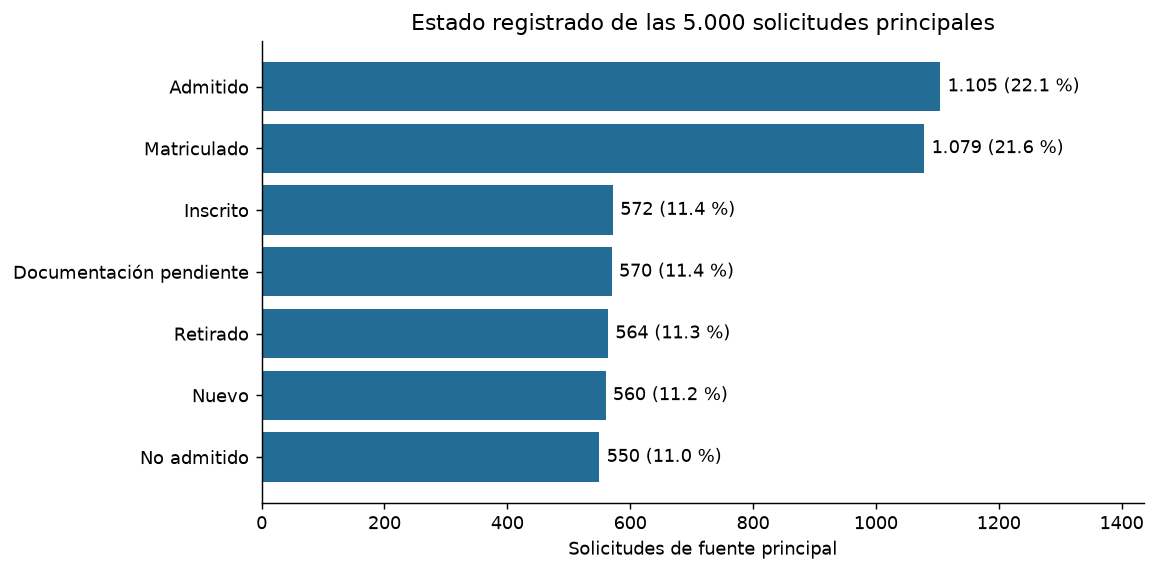

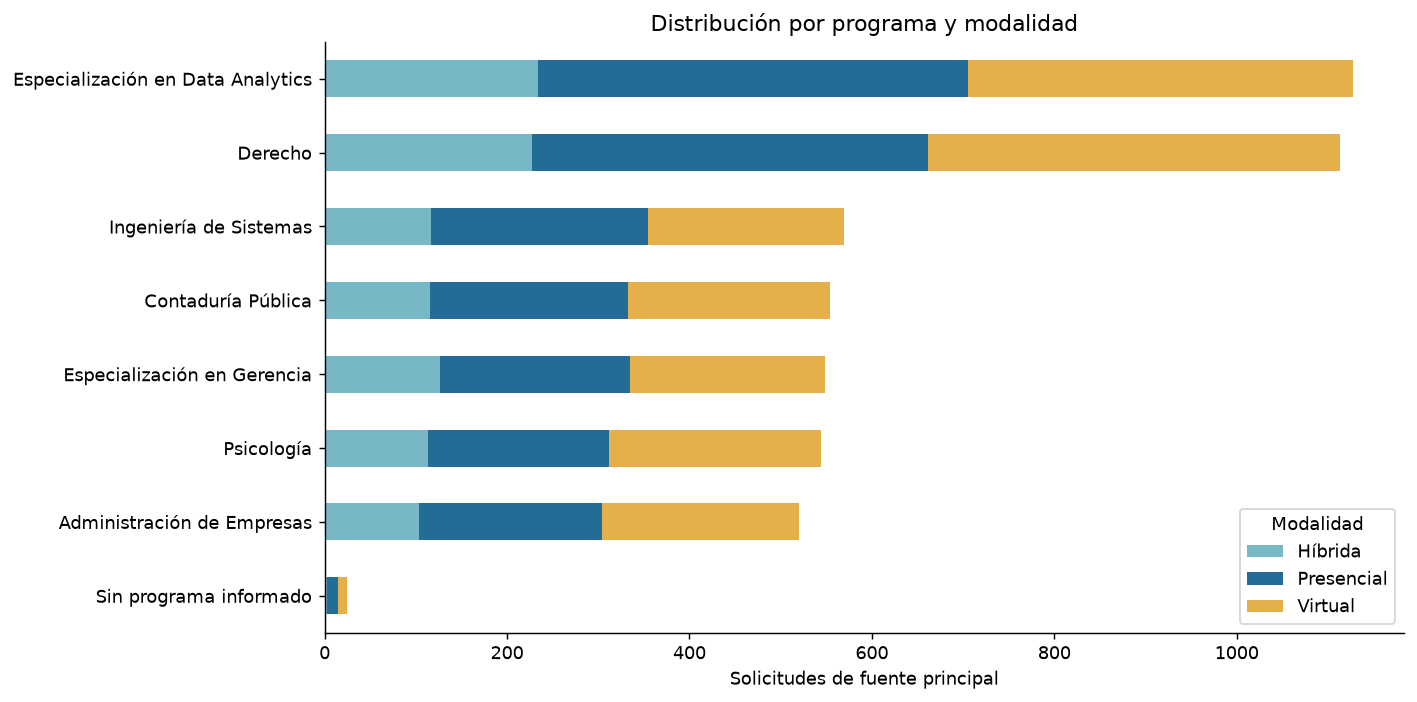

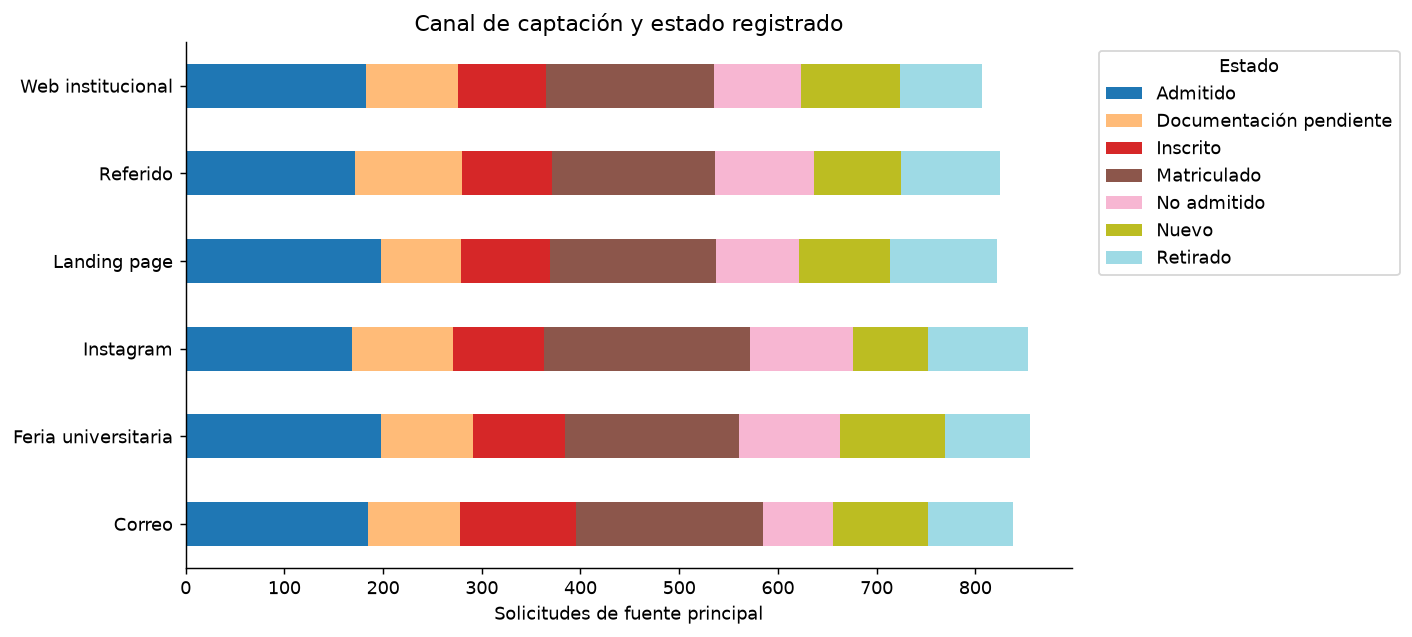

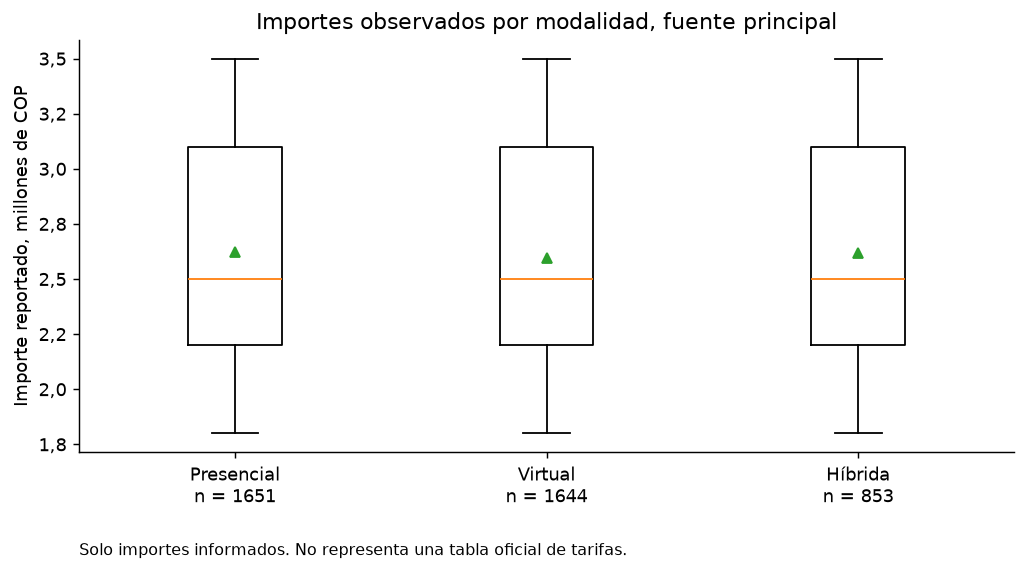

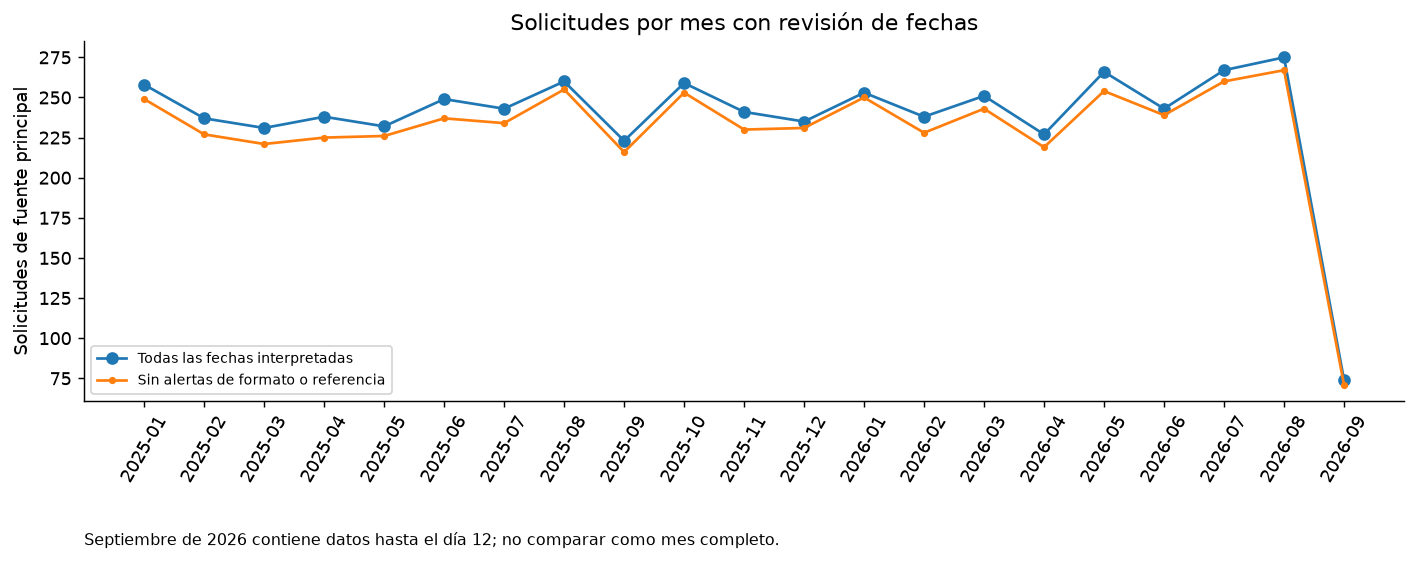

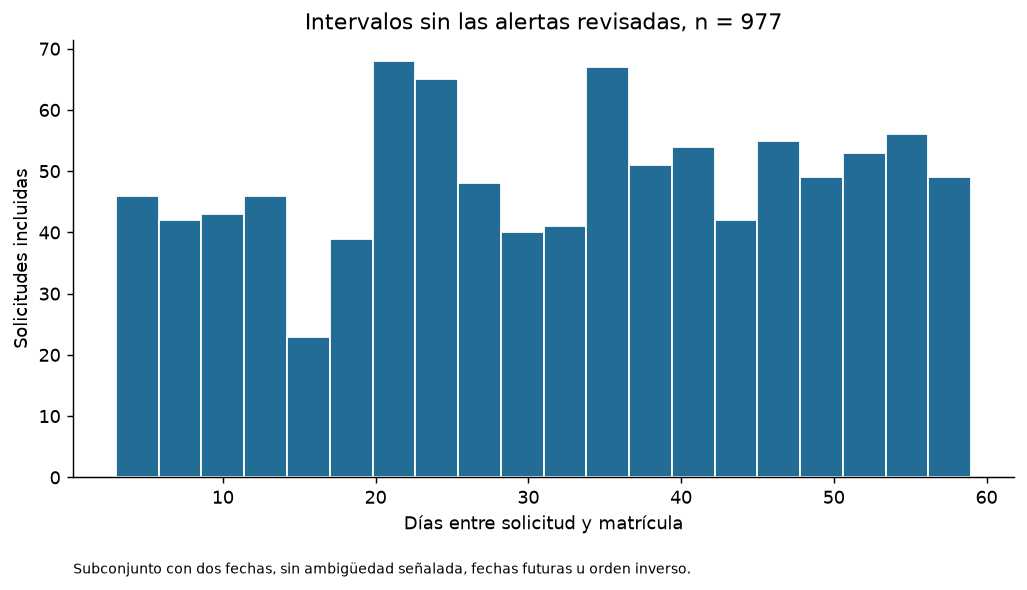

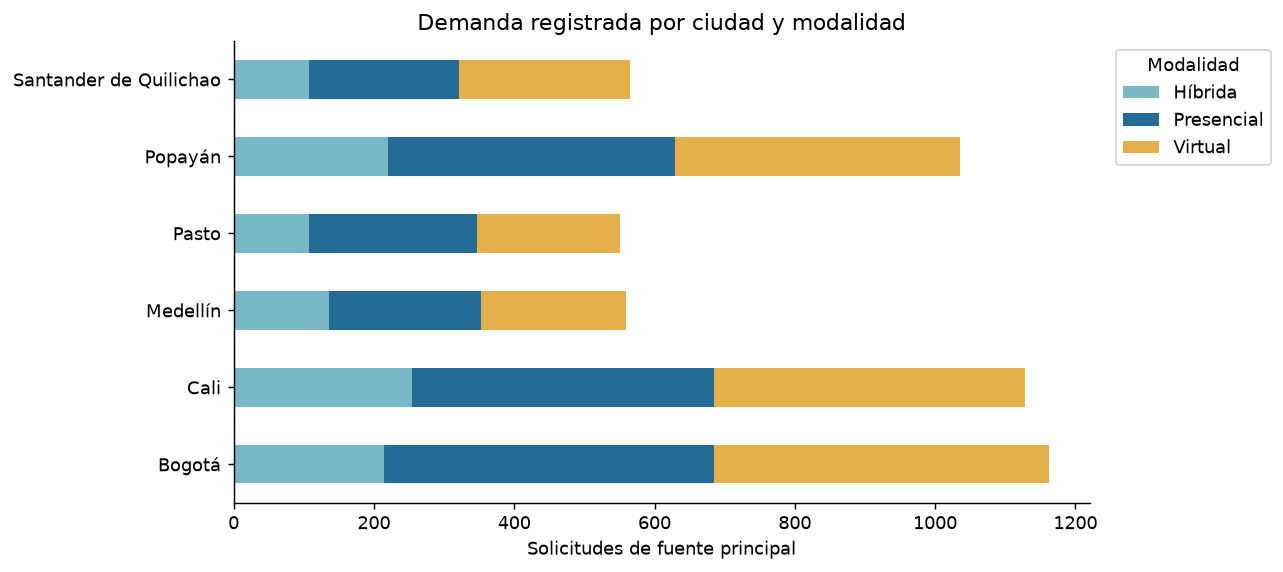

In [29]:
from IPython.display import Image
figuras_revision = revision.graficar()
for figura in figuras_revision:
    display(Image(filename=str(figura)))

### Salidas actuales y controles

El Excel mantiene el consolidado de 5.600 registros y una hoja Principal_Analisis
de 5.000 códigos principales distintos. Los controles permanecen separados.
Estas dos vistas no deben sumarse entre sí. CRM y Oracle aún requieren conciliación.

In [30]:
resumen_revision = revision.exportar(preserve_empty_text)
df_revision = pd.DataFrame(revision.all, columns=HEADERS, index=revision.ids_out, dtype=object)
df_principal = pd.DataFrame(revision.main, columns=HEADERS, index=revision.main_ids, dtype=object)
df_revision.index.name = df_principal.index.name = 'id_registro_salida'
display(df_principal.head())
display(pd.read_csv(revision.audit / 'controles.csv', encoding='utf-8-sig'))
texto_revision = (ROOT / 'reports/limpieza/revision_descriptiva_y_parciales.md').read_text()
display(Markdown(texto_revision.split('## Gráficos')[0]))
print('Datos actuales:', resumen_revision['datos_salida'])
print('Tablas, calidad y trazabilidad:', resumen_revision['auditoria'])

,registro_id,aspirante_id,fecha_solicitud,programa,modalidad,canal_captacion,estado_proceso,puntaje_admision,documentos_completos,valor_matricula_cop,ciudad_residencia,asesor,fecha_matricula,correo,periodo_academico,facultad,duracion_semestres,nivel_formacion
id_registro_salida,,,,,,,,,,,,,,,,,,
BU000001,REG004364,A003446,2026-07-28,Derecho,Virtual,Instagram,Inscrito,45.0,Sí,2200000.00,Cali,Asesor 1,None,aspirante003446@ejemplo.com,20262,Ciencias Sociales,8,Pregrado
BU000002,REG002946,A000009,2026-07-22,Derecho,Virtual,Landing page,Matriculado,91.0,Sí,2500000.00,Medellín,Asesor 1,2026-09-17,aspirante000009@ejemplo.com,20252,Ciencias Sociales,8,Pregrado
BU000003,REG000889,A004142,2025-01-27,Administración de Empresas,Presencial,Correo,Admitido,71.0,Sí,2500000.00,Pasto,Asesor 1,None,aspirante004142@ejemplo.com,20252,Ciencias Económicas,10,Pregrado
BU000004,REG002419,A001328,2025-09-09,Especialización en Gerencia,Virtual,Correo,Admitido,46.0,Sí,None,Bogotá,Asesor 3,None,aspirante001328@ejemplo.com,20262,Ciencias Económicas,2,Posgrado
BU000005,REG003130,A002366,2026-01-04,Ingeniería de Sistemas,Virtual,Correo,Nuevo,66.0,Sí,2200000.00,Popayán,Asesor 1,None,aspirante002366@ejemplo.com,20262,Ingeniería,8,Pregrado


,control,correcto
0,5602 menos dos consolidados igual 5600,True
1,18 columnas originales,True
2,Cinco celdas recuperadas y solo ausencias de I...,True
3,Estados conservados,True
4,Importes no imputados,True
5,Fechas e identificadores informados conservados,True
6,Sin nan o textos vacíos en identificadores,True
7,5000 códigos principales únicos,True
8,5640 entradas con destino,True
9,Destinos existentes,True


# Revisión descriptiva y avance de limpieza

Fecha: 26 de octubre de 2026.

**Resultado:** los dos registros parciales se complementaron y consolidaron. El consolidado conserva 5.600 registros y 18 columnas. La fuente principal contiene 5.000 códigos de solicitud distintos; CRM aporta 100 registros solapados y Oracle 500 registros con correspondencias candidatas. Las comparaciones administrativas siguientes utilizan la fuente principal, sin sumar CRM y Oracle como solicitudes adicionales.

## 1. Qué se corrigió

| Solicitud | Tratamiento |
| :--- | :--- |
| REG003600 | Se recuperó 1.800.000 COP de su otra fila y se consolidaron las dos entradas. |
| REG004804 | Se recuperaron Ingeniería de Sistemas, Ingeniería, 8 semestres y Pregrado desde su otra fila, y se consolidaron ambas entradas. |

Se comprobó la igualdad de todos los demás atributos, incluido el código de solicitud, antes de complementar las ausencias. Se recuperaron cinco celdas y se consolidaron dos filas; no se imputaron promedios ni se eligió entre valores informados contradictorios. La auditoría mantiene el destino de las 5.640 entradas originales.

Se homologaron como ausencias reales 94 identificadores no informados, incluidos 4 textos nan. Son null en JSONL, None en Python y celdas vacías en Excel. Se conserva el marcador original y su motivo en L10_ausencias_identificadores.csv. No se eliminó ninguna solicitud por esta normalización y se conservaron los códigos informados.

## 2. Estados: Nuevo no se reclasifica como Admitido

Las fuentes utilizan ambas etiquetas y no contienen un diccionario que las declare equivalentes. La presencia de puntaje o documentos completos tampoco demuestra admisión. Se conservan los siete estados y se ofrece una agrupación auxiliar para presentar el proceso, sin afirmar transiciones.

| Estado registrado | Solicitudes principales | Porcentaje | Fase auxiliar de presentación |
| :--- | ---: | ---: | :--- |
| Admitido | 1.105 | 22.10 % | Admisión registrada |
| Matriculado | 1.079 | 21.58 % | Matrícula registrada |
| Inscrito | 572 | 11.44 % | Gestión inicial |
| Documentación pendiente | 570 | 11.40 % | Gestión inicial |
| Retirado | 564 | 11.28 % | Retirado |
| Nuevo | 560 | 11.20 % | Gestión inicial |
| No admitido | 550 | 11.00 % | No admitido |

Hay 351 solicitudes con estado Documentación pendiente y documentos Sí, y 462 con estado Matriculado y documentos No o Pendiente. Son discrepancias para seguimiento, no una regla para sustituir automáticamente el estado. También podrían reflejar estados o documentos actualizados en momentos distintos; esa explicación es una hipótesis.

## 3. Importes por programa, modalidad y periodo

Las 63 combinaciones de programa identificado, modalidad y periodo de la fuente principal contienen cinco importes distintos. Ninguna tiene una tarifa única deducible. No se puede completar una matrícula solo porque otra solicitud tenga el mismo programa y modalidad.

| Modalidad | Importes informados | Ausentes | Promedio COP | Mediana COP |
| :--- | ---: | ---: | ---: | ---: |
| Virtual | 1.644 | 337 | 2.595.620,44 | 2.500.000,00 |
| Presencial | 1.651 | 329 | 2.624.348,88 | 2.500.000,00 |
| Híbrida | 853 | 186 | 2.616.178,19 | 2.500.000,00 |

En las 21 comparaciones dentro de un mismo programa y periodo, la mediana virtual es menor en 1, igual en 18 y mayor en 2. Esto describe los importes disponibles y no acredita que una modalidad tenga una tarifa más baja. No se aplicó imputación por modalidad.

CRM conserva un concepto distinto: base más derechos administrativos. Sus importes se describen por separado. La comprobación anterior encontró 87 matrículas principales iguales a la base CRM y 13 principales ausentes recuperables desde la base CRM; esa conciliación económica es una regla pendiente de aplicar y no forma parte de las cinco celdas recuperadas aquí.

## 4. Las fechas de matrícula sí aportan

En la fuente principal, los 1.079 registros con estado Matriculado tienen fecha de matrícula y no se observan fechas de matrícula en otros estados. Por ello la columna aporta información para estudiar cuándo se registra la matrícula y el intervalo frente a la solicitud.

Se detectan 165 fechas de solicitud con formato ambiguo señalado y 0 matrículas anteriores a la solicitud. El resumen de intervalos utiliza 977 casos sin las alertas revisadas y deja fuera del cálculo 102; estos últimos permanecen en la base. La mediana del subconjunto es 33 días. No representa un tiempo promedio institucional validado.

La fuente principal llega hasta 2026-09-12. Septiembre de 2026 termina en el día 12: una caída de su conteo no demuestra una caída mensual de demanda. Oracle tiene otra cobertura temporal y no se mezcla en esta serie. Las fechas no se intercambiaron ni se ajustaron a un periodo supuesto.

## 5. Aporte de aspirante_id

Los 5.000 códigos de solicitud principales contienen 2.924 códigos de aspirante informados distintos. Hay 90 solicitudes sin código de aspirante y 1.363 códigos presentes en varias solicitudes. Solicitud y aspirante son unidades diferentes.

Entre los identificadores ausentes, 62 tienen un único código candidato en otras filas con el mismo correo. Esa coincidencia se exporta para revisión y no se aplica como prueba de identidad. Se conserva aspirante_id en el respaldo y se omite de las agrupaciones de mercado; borrarlo impediría revisar recurrencia y procedencia.

## 6. Lectura administrativa y oportunidades de análisis

Los cruces de programa, modalidad y ciudad permiten describir dónde se concentra la demanda registrada. Los cruces de canal y estado permiten ubicar solicitudes en gestión inicial o con matrícula registrada. Sus cantidades y proporciones se exportan con el denominador de cada grupo.

Una concentración de solicitudes identifica interés observado. Para llamarla oportunidad comercial conviene considerar también costos, capacidad y campañas, que no están disponibles. La proporción de registros Matriculado por canal no mide por sí sola la eficacia causal ni una conversión comercial definitiva. Los datos disponibles tampoco permiten reconstruir cuánto duró cada etapa del proceso, porque no hay fechas de transición de estado.

Preguntas útiles: ¿qué combinaciones de programa, modalidad y ciudad concentran solicitudes? ¿Qué canales concentran gestión inicial y matrícula registrada? ¿Dónde hay estados y documentación discordantes? ¿Cómo cambian las fechas de matrícula dentro del subconjunto sin alertas? ¿Qué solicitudes repiten código de aspirante?

## 7. Qué queda pendiente para la versión definitiva

| Tema | Siguiente tratamiento |
| :--- | :--- |
| CRM | Aprobar y aplicar la conciliación de 100 correspondencias y el concepto económico antes de recuperar los 13 importes. |
| Oracle | Acordar la regla de identidad para integrar sus candidatos; conservarlo separado del volumen principal mientras tanto. |
| Fechas y periodos | Conservar valores, indicar casos no elegibles para cada cálculo y resolver solo con evidencia interna suficiente. |
| Estados y catálogo | Mantener denominaciones actuales; usar agrupaciones auxiliares explícitas. No convertir Nuevo en Admitido. |
| Vacíos | Mantener ausencias no recuperables. No completar importes por programa o modalidad sin una regla sustentada. |

Pasaron 15 controles, incluida la lectura completa de CSV, Excel y JSONL. Los estados, códigos informados, fechas e importes ajenos a REG003600 conservan sus valores; los identificadores no informados se representan como null. La salida permite continuar análisis descriptivo por fuente; la identidad global y los conceptos económicos todavía requieren reglas de cierre.



Datos actuales: data/processed/taller_2/revision_descriptiva_v1_9fbbe58562_b04de70c_03c823d0_cd91e63a
Tablas, calidad y trazabilidad: reports/limpieza/ejecuciones/revision_descriptiva_v1_9fbbe58562_b04de70c_03c823d0_cd91e63a


## Qué falta para aprobar la versión final

L03 ya distingue las ausencias de las demás variables. Los cuatro nan y los vacíos de
aspirante_id se mantienen registrados y sin modificar hasta la revisión de cruces.
L04 ya representa fechas y números y utiliza el código entero del periodo.
Las fechas dudosas y los importes con conceptos diferentes siguen señalados.

L05 revisó el catálogo; L06 consolidó repeticiones exactas con trazabilidad; L07
identificó conflictos entre fuentes. L08 documentó la coherencia administrativa y
L09 exportó la versión de revisión, sus controles y las decisiones pendientes.
L10 complementó y consolidó REG003600 y REG004804. La salida vigente contiene
5.600 registros y la cohorte principal 5.000 códigos de solicitud distintos.
Las decisiones del reporte deben validarse y aplicarse mediante reglas versionadas
antes de aprobar solicitudes únicas y los indicadores administrativos definitivos.

El notebook anterior sigue respaldando la exploración inicial de 5.040 filas. Este
cuaderno respalda el trabajo sobre la base consolidada de 5.640 filas.